# CELL 1: LOCAL ENVIRONMENT, GPU CHECK & AUTHENTICATION

In [1]:
# ==============================================================================
# CELL 1: LOCAL ENVIRONMENT, GPU CHECK & AUTHENTICATION
# ==============================================================================
import os
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM Total: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("WARNING: CUDA is not active! Ensure you installed the CUDA-enabled PyTorch build.")

# Optional Hugging Face login (uses local environment variable if set)
try:
    from huggingface_hub import login
    hf_token = os.environ.get("HF_TOKEN", None)
    if hf_token:
        login(token=hf_token)
        print("Authenticated with Hugging Face Hub using local HF_TOKEN.")
    else:
        print("No local HF_TOKEN needed; public SegFormer weights will download directly.")
except ImportError:
    print("huggingface_hub not installed; transformers will still download public weights.")

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
PyTorch: 2.14.0+cpu
CUDA available: False


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Authenticated with Hugging Face Hub using local HF_TOKEN.


# CELL 2: IMPORTS, GLOBAL SEED & LOCAL EXPERIMENT CONFIGURATION

In [2]:
# ==============================================================================
# CELL 2: IMPORTS, GLOBAL SEED & LOCAL EXPERIMENT CONFIGURATION
# ==============================================================================
import os
import glob
import json
import random
import time
import gc
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
import transformers
from transformers import SegformerForSemanticSegmentation

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    jaccard_score, classification_report, confusion_matrix, balanced_accuracy_score
)

# Silence the expected UNEXPECTED/MISSING head initialization table from transformers
transformers.utils.logging.set_verbosity_error()

# Global reproducibility seed
SEED = 42
random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Experiment configuration tailored for 8GB RTX 5050 + 24GB RAM + 1TB NVMe SSD
IMAGE_SIZE = (512, 1024)    # Full resolution (Height, Width)
NUM_CLASSES = 26            # 26 IDD Level-3 classes
IGNORE_INDEX = 255
EPOCHS = 25
LR_BACKBONE = 6e-5
LR_HEAD = 6e-4
WEIGHT_DECAY = 0.01
DROPOUT_RATE = 0.10
BATCH_SIZE = 4              # Physical batch size for 8GB VRAM at 512x1024
GRAD_ACCUM_STEPS = 4        # Effective batch size = 16
NUM_WORKERS = 0             # Required on Windows Jupyter to avoid multiprocessing spawn errors

PRETRAINED_MAP = {
    "segformer_b0": "nvidia/mit-b0",
    "segformer_b1": "nvidia/mit-b1",
}

OUTPUT_DIR = Path("./aciids2027_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"
MASK_CACHE_DIR = OUTPUT_DIR / f"mask_cache_{IMAGE_SIZE[0]}x{IMAGE_SIZE[1]}"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MASK_CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Local Output directory:", OUTPUT_DIR.resolve())
print("Local NVMe Mask Cache :", MASK_CACHE_DIR.resolve())
print("Target epochs per model:", EPOCHS)
print("Effective batch size:", BATCH_SIZE * GRAD_ACCUM_STEPS)

Device: cpu
Local Output directory: D:\IDD_Research\aciids2027_outputs
Local NVMe Mask Cache : D:\IDD_Research\aciids2027_outputs\mask_cache_512x1024
Target epochs per model: 25
Effective batch size: 16


# CELL 3: DOWNLOAD AND LOCATE THE DATASET LOCALLY

In [3]:
# ==============================================================================
# CELL 3: AUTO-LOCATE IDD DATASET STRUCTURE (PORTABLE & MULTI-DRIVE)
# ==============================================================================
from pathlib import Path
import string

def find_idd_dataset():
    # 1. Check relative to current working directory
    current_dir = Path().resolve()
    for parent in [current_dir] + list(current_dir.parents):
        candidate = parent / "idd20kI"
        if (candidate / "leftImg8bit").is_dir():
            return candidate
        for p in candidate.glob("**/leftImg8bit"):
            if p.is_dir():
                return p.parent

    # 2. Check user home directory (e.g., ~/IDD_Research/idd20kI)
    home_candidate = Path.home() / "IDD_Research" / "idd20kI"
    if (home_candidate / "leftImg8bit").is_dir():
        return home_candidate
    for p in home_candidate.glob("**/leftImg8bit"):
        if p.is_dir():
            return p.parent

    # 3. Scan root directories of all connected drives (C:, D:, E:, etc.)
    available_drives = [Path(f"{d}:\\") for d in string.ascii_uppercase if Path(f"{d}:\\").exists()]
    for drive in available_drives:
        for candidate in drive.glob("**/idd20kI"):
            if (candidate / "leftImg8bit").is_dir():
                return candidate

    return None

DATA_ROOT = find_idd_dataset()

if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not automatically locate 'idd20kI' on any connected drive or folder. "
        "Please ensure the dataset folder is extracted correctly."
    )

train_img_dir = DATA_ROOT / "leftImg8bit" / "train"
val_img_dir   = DATA_ROOT / "leftImg8bit" / "val"
train_gt_dir  = DATA_ROOT / "gtFine" / "train"
val_gt_dir    = DATA_ROOT / "gtFine" / "val"

print("Dataset root successfully located at:", DATA_ROOT.resolve())
print("train exists:", train_img_dir.is_dir(), "| val exists:", val_img_dir.is_dir())

Dataset root successfully located at: D:\IDD_Dataset\idd20kI
train exists: True | val exists: True


# CELL 4: PAIR SAMPLES, RECREATE FIXED SPLIT (SEED 42) & SAVE CONFIG

In [4]:
# ==============================================================================
# CELL 4: PAIR SAMPLES, RECREATE FIXED SPLIT (SEED 42) & SAVE CONFIG
# ==============================================================================
IDD_LEVEL3_NAMES = [
    "road", "parking", "sidewalk", "rail track", "building", "wall", "fence",
    "guard rail", "bridge", "tunnel", "pole", "traffic light", "traffic sign",
    "vegetation", "terrain", "sky", "person", "rider", "car", "truck", "bus",
    "train", "motorcycle", "bicycle", "autorickshaw", "animal"
]

IDD_LEVEL3_MAPPING = {name: idx for idx, name in enumerate(IDD_LEVEL3_NAMES)}
IDD_LEVEL3_MAPPING["polegroup"] = 10  # Group polegroup into pole (class 10)

def pair_idd_samples(root_dir: Path, split: str):
    img_dir = root_dir / "leftImg8bit" / split
    gt_dir  = root_dir / "gtFine" / split
    samples = []

    img_paths = sorted(
        glob.glob(str(img_dir / "**" / "*.png"), recursive=True) +
        glob.glob(str(img_dir / "**" / "*.jpg"), recursive=True)
    )
    for img_p in img_paths:
        img_path = Path(img_p)
        rel_path = img_path.relative_to(img_dir)
        base_name = img_path.name
        for suf in ["_leftImg8bit.png", "_leftImg8bit.jpg", "_leftImg8bit"]:
            if base_name.endswith(suf):
                base_name = base_name[:-len(suf)]
                break
        base_name = Path(base_name).stem
        json_path = (gt_dir / rel_path.parent) / f"{base_name}_gtFine_polygons.json"
        if json_path.exists():
            samples.append((str(img_path), str(json_path)))
    return samples

train_samples = pair_idd_samples(DATA_ROOT, "train")
val_samples   = pair_idd_samples(DATA_ROOT, "val")

val_indices = np.arange(len(val_samples))
cal_indices, holdout_indices = train_test_split(
    val_indices,
    test_size=0.70,
    random_state=SEED
)

cal_samples     = [val_samples[i] for i in cal_indices]
holdout_samples = [val_samples[i] for i in holdout_indices]

print(f"Total paired train samples  : {len(train_samples)}")
print(f"Total paired val samples    : {len(val_samples)}")
print(f"Calibration samples (30%)   : {len(cal_samples)}")
print(f"Holdout eval samples (70%)  : {len(holdout_samples)}")

np.savez_compressed(
    OUTPUT_DIR / "split_indices_seed42.npz",
    cal_indices=cal_indices,
    holdout_indices=holdout_indices,
    class_names=np.array(IDD_LEVEL3_NAMES)
)

with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump({
        "dataset_id": "sounakp/idd-segmentation",
        "dataset_root": str(DATA_ROOT),
        "seed": SEED,
        "image_size": IMAGE_SIZE,
        "num_classes": NUM_CLASSES,
        "train_count": len(train_samples),
        "calibration_count": len(cal_samples),
        "holdout_count": len(holdout_samples),
        "epochs": EPOCHS,
        "lr_backbone": LR_BACKBONE,
        "lr_head": LR_HEAD,
        "weight_decay": WEIGHT_DECAY,
        "dropout_rate": DROPOUT_RATE,
        "physical_batch_size": BATCH_SIZE,
        "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    }, f, indent=2)

Total paired train samples  : 6993
Total paired val samples    : 981
Calibration samples (30%)   : 294
Holdout eval samples (70%)  : 687


In [5]:
# ==============================================================================
# CELL 5: DATASET CLASS WITH NVME MASK CACHING & DATALOADERS
# ==============================================================================
def get_label_id(label_name: str) -> int:
    name = label_name.lower().strip()
    for key, val in IDD_LEVEL3_MAPPING.items():
        if key in name:
            return val
    return IGNORE_INDEX

class IDDSegmentationDataset(Dataset):
    MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __init__(self, samples, image_size=(512, 1024), augment=False, cache_dir=MASK_CACHE_DIR):
        self.samples = samples
        self.image_size = image_size
        self.augment = augment
        self.cache_dir = Path(cache_dir)

    def __len__(self):
        return len(self.samples)

    def _load_or_render_mask(self, json_path: str, H: int, W: int) -> np.ndarray:
        jp = Path(json_path)
        cache_file = self.cache_dir / f"{jp.parent.name}_{jp.stem}_{H}x{W}.png"

        if cache_file.exists():
            gt_pil = Image.open(cache_file)
            mask_np = np.array(gt_pil, dtype=np.int64)
        else:
            with open(jp, "r", encoding="utf-8") as f:
                json_data = json.load(f)

            orig_w = json_data.get("imgWidth", W)
            orig_h = json_data.get("imgHeight", H)

            mask_img = Image.new("L", (orig_w, orig_h), IGNORE_INDEX)
            draw = ImageDraw.Draw(mask_img)

            for obj in json_data.get("objects", []):
                label = obj.get("label", "")
                polygon = obj.get("polygon", [])
                class_id = get_label_id(label)
                if polygon and len(polygon) >= 3:
                    flat_coords = [(pt[0], pt[1]) for pt in polygon]
                    draw.polygon(flat_coords, fill=class_id)

            gt_pil = mask_img.resize((W, H), resample=Image.NEAREST)
            gt_pil.save(cache_file)
            mask_np = np.array(gt_pil, dtype=np.int64)

        mask_np[(mask_np < 0) | (mask_np >= NUM_CLASSES)] = IGNORE_INDEX
        return mask_np

    def __getitem__(self, idx):
        H, W = self.image_size
        img_path, json_path = self.samples[idx]

        # 1. Load and resize RGB image
        img_pil = Image.open(img_path).convert("RGB").resize((W, H), resample=Image.BILINEAR)
        img_np = np.array(img_pil, dtype=np.uint8)

        # 2. Load cached mask from NVMe SSD (or render from JSON on first pass)
        mask_np = self._load_or_render_mask(json_path, H, W)

        # 3. Random horizontal flip augmentation for training
        if self.augment and np.random.rand() > 0.5:
            img_np = np.ascontiguousarray(img_np[:, ::-1, :])
            mask_np = np.ascontiguousarray(mask_np[:, ::-1])

        # 4. Normalize and convert to PyTorch tensors
        img_float = (img_np.astype(np.float32) / 255.0 - self.MEAN) / self.STD
        img_tensor = torch.from_numpy(img_float).permute(2, 0, 1).contiguous()
        mask_tensor = torch.from_numpy(mask_np).long()

        return img_tensor, mask_tensor

train_dataset   = IDDSegmentationDataset(train_samples,   image_size=IMAGE_SIZE, augment=True)
cal_dataset     = IDDSegmentationDataset(cal_samples,     image_size=IMAGE_SIZE, augment=False)
holdout_dataset = IDDSegmentationDataset(holdout_samples, image_size=IMAGE_SIZE, augment=False)

loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": True if DEVICE.type == "cuda" else False,
}

train_loader   = DataLoader(train_dataset,   shuffle=True,  **loader_common)
cal_loader     = DataLoader(cal_dataset,     shuffle=False, **loader_common)
holdout_loader = DataLoader(holdout_dataset, shuffle=False, **loader_common)

print("Train batches:", len(train_loader))
print("Calibration batches:", len(cal_loader))
print("Holdout batches:", len(holdout_loader))

# Sanity check
xb, yb = next(iter(train_loader))
print("Batch images:", tuple(xb.shape), "| label shape:", tuple(yb.shape))
del xb, yb

Train batches: 1749
Calibration batches: 74
Holdout batches: 172
Batch images: (4, 3, 512, 1024) | label shape: (4, 512, 1024)


In [6]:
# ==============================================================================
# CELL 6: MODEL DEFINITIONS WITH DROPOUT REGULARIZATION
# ==============================================================================
def build_model(model_name: str, dropout_rate: float = DROPOUT_RATE) -> nn.Module:
    """Build SegFormer-B0 or SegFormer-B1 with 10% dropout regularization."""
    if model_name not in PRETRAINED_MAP:
        raise ValueError(f"Unknown model name: {model_name}. Choose from {list(PRETRAINED_MAP.keys())}")

    pretrained_name = PRETRAINED_MAP[model_name]
    id2label = {i: IDD_LEVEL3_NAMES[i] for i in range(NUM_CLASSES)}
    label2id = {IDD_LEVEL3_NAMES[i]: i for i in range(NUM_CLASSES)}

    model = SegformerForSemanticSegmentation.from_pretrained(
        pretrained_name,
        num_labels=NUM_CLASSES,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True,
        hidden_dropout_prob=dropout_rate,
        attention_probs_dropout_prob=dropout_rate,
        classifier_dropout_prob=dropout_rate,
    )
    return model

# Model shape test (Supports both CUDA and CPU)
if DEVICE.type == "cuda":
    _model = build_model("segformer_b0").to(DEVICE)
    with torch.no_grad():
        _out = _model(pixel_values=torch.zeros(2, 3, IMAGE_SIZE[0], IMAGE_SIZE[1], device=DEVICE))
    print("SegFormer logits output shape (GPU):", tuple(_out.logits.shape))
    del _model, _out
    torch.cuda.empty_cache()
    gc.collect()
else:
    print("Running model shape test on CPU...")
    _model = build_model("segformer_b0").to(DEVICE)
    with torch.no_grad():
        _out = _model(pixel_values=torch.zeros(1, 3, IMAGE_SIZE[0], IMAGE_SIZE[1], device=DEVICE))
    print("SegFormer logits output shape (CPU):", tuple(_out.logits.shape))
    del _model, _out
    gc.collect()

Running model shape test on CPU...


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

SegFormer logits output shape (CPU): (1, 26, 128, 256)


In [7]:
# ==============================================================================
# CELL 7: TRAINING WITH PER-EPOCH CHECKPOINTS, AMP & EARLY STOPPING
# ==============================================================================
def checkpoint_path(model_name: str) -> Path:
    return CHECKPOINT_DIR / f"{model_name}_last.pt"

def best_checkpoint_path(model_name: str) -> Path:
    return CHECKPOINT_DIR / f"{model_name}_best.pt"

def train_model(model_name: str, model: nn.Module, epochs: int = EPOCHS, patience: int = 5, min_delta: float = 1e-4, max_grad_norm: float = 1.0):
    if DEVICE.type != "cuda":
        print("Notice: GPU not detected. Skipping training function execution on CPU-only setup.")
        return model, []
    else:
        model = model.to(DEVICE)
        
    optimizer = AdamW([
        {"params": model.segformer.parameters(), "lr": LR_BACKBONE, "weight_decay": WEIGHT_DECAY},
        {"params": model.decode_head.parameters(), "lr": LR_HEAD, "weight_decay": WEIGHT_DECAY}
    ])
    total_steps = epochs * len(train_loader)
    scheduler = CosineAnnealingLR(optimizer, T_max=total_steps, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=True)

    ckpt_path = checkpoint_path(model_name)
    best_path = best_checkpoint_path(model_name)
    history = []
    start_epoch = 0
    best_loss = float("inf")
    epochs_without_improvement = 0

    if ckpt_path.exists():
        checkpoint = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        if "scheduler_state_dict" in checkpoint:
            scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
        if "scaler_state_dict" in checkpoint:
            scaler.load_state_dict(checkpoint["scaler_state_dict"])
        start_epoch = int(checkpoint["epoch"])
        history = checkpoint.get("history", [])
        best_loss = float(checkpoint.get("best_loss", float("inf")))
        print(f"Resuming {model_name} from completed epoch {start_epoch}/{epochs}")

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss = 0.0
        correct_pixels = 0
        valid_pixels = 0
        samples = 0
        nan_detected = False

        optimizer.zero_grad(set_to_none=True)
        start_time = time.time()
        progress = tqdm(
            enumerate(train_loader),
            total=len(train_loader),
            desc=f"{model_name} | epoch {epoch+1}/{epochs}"
        )

        for batch_i, (images, targets) in progress:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=True):
                outputs = model(pixel_values=images, labels=targets)
                raw_loss = outputs.loss
                loss = raw_loss / GRAD_ACCUM_STEPS

            if torch.isnan(raw_loss) or torch.isinf(raw_loss):
                print(f"\n[CRITICAL ERROR] Loss became {raw_loss.item()} at epoch {epoch+1}, step {batch_i}! Stopping training.")
                nan_detected = True
                break

            scaler.scale(loss).backward()

            should_step = ((batch_i + 1) % GRAD_ACCUM_STEPS == 0) or ((batch_i + 1) == len(train_loader))
            if should_step:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)

            scheduler.step()

            # Compute live pixel accuracy
            with torch.no_grad():
                up_logits = F.interpolate(outputs.logits.detach(), size=targets.shape[-2:], mode="bilinear", align_corners=False)
                preds = up_logits.argmax(dim=1)
                valid_mask = (targets != IGNORE_INDEX)
                correct_pixels += int((preds[valid_mask] == targets[valid_mask]).sum().item())
                valid_pixels += int(valid_mask.sum().item())

            batch_n = targets.size(0)
            running_loss += float(raw_loss.detach()) * batch_n
            samples += batch_n

            live_loss = running_loss / max(samples, 1)
            live_acc  = correct_pixels / max(valid_pixels, 1)
            progress.set_postfix(acc=f"{live_acc:.4f}", loss=f"{live_loss:.4f}")

        if nan_detected:
            break

        epoch_loss = running_loss / max(samples, 1)
        epoch_acc  = correct_pixels / max(valid_pixels, 1)
        row = {
            "model": model_name,
            "epoch": epoch + 1,
            "train_loss": epoch_loss,
            "train_accuracy": epoch_acc,
            "seconds": time.time() - start_time,
        }
        history.append(row)
        pd.DataFrame(history).to_csv(OUTPUT_DIR / f"{model_name}_training_history.csv", index=False)

        # Save best checkpoint & check for loss stagnation
        if epoch_loss < (best_loss - min_delta):
            best_loss = epoch_loss
            epochs_without_improvement = 0
            torch.save(model.state_dict(), best_path)
        else:
            epochs_without_improvement += 1

        torch.save({
            "model_name": model_name,
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
            "best_loss": best_loss,
            "seed": SEED,
            "class_names": IDD_LEVEL3_NAMES,
        }, ckpt_path)

        gc.collect()
        torch.cuda.empty_cache()

        print(f"Saved checkpoint: {ckpt_path} | epoch {epoch+1}/{epochs} | train loss {epoch_loss:.4f} | train acc {epoch_acc:.4f} | time {row['seconds']:.1f}s")

        if epochs_without_improvement >= patience:
            print("training stopped due to no change")
            break

    return model, history

In [8]:
# ==============================================================================
# CELL 8: HOLDOUT EVALUATION & SKLEARN METRICS
# ==============================================================================
def evaluate_model(model_name: str, model: nn.Module):
    best_path = best_checkpoint_path(model_name)
    if best_path.exists():
        model.load_state_dict(torch.load(best_path, map_location=DEVICE))

    model.eval()
    y_true, y_pred = [], []
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, targets in tqdm(holdout_loader, desc=f"Evaluating {model_name}"):
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                outputs = model(pixel_values=images, labels=targets)
                loss = outputs.loss
                up_logits = F.interpolate(outputs.logits, size=targets.shape[-2:], mode="bilinear", align_corners=False)

            total_loss += float(loss.detach()) * targets.size(0)
            total_samples += targets.size(0)

            preds = up_logits.argmax(dim=1)

            # Subsample 4x4 grid to keep evaluation fast and within RAM limits
            preds_sub   = preds[:, ::4, ::4].cpu().numpy().flatten()
            targets_sub = targets[:, ::4, ::4].cpu().numpy().flatten()

            valid_mask = (targets_sub != IGNORE_INDEX)
            y_true.extend(targets_sub[valid_mask].tolist())
            y_pred.extend(preds_sub[valid_mask].tolist())

    all_labels = list(range(NUM_CLASSES))
    acc             = accuracy_score(y_true, y_pred)
    macro_miou      = jaccard_score(y_true, y_pred, labels=all_labels, average="macro", zero_division=0)
    weighted_miou   = jaccard_score(y_true, y_pred, labels=all_labels, average="weighted", zero_division=0)
    macro_f1        = f1_score(y_true, y_pred, labels=all_labels, average="macro", zero_division=0)
    weighted_f1     = f1_score(y_true, y_pred, labels=all_labels, average="weighted", zero_division=0)
    macro_precision = precision_score(y_true, y_pred, labels=all_labels, average="macro", zero_division=0)
    macro_recall    = recall_score(y_true, y_pred, labels=all_labels, average="macro", zero_division=0)
    bal_acc         = balanced_accuracy_score(y_true, y_pred)

    cm = confusion_matrix(y_true, y_pred, labels=all_labels)
    report_dict = classification_report(
        y_true, y_pred, labels=all_labels, target_names=IDD_LEVEL3_NAMES,
        output_dict=True, zero_division=0
    )

    metrics = {
        "model": model_name,
        "holdout_count": total_samples,
        "holdout_loss": total_loss / max(total_samples, 1),
        "pixel_accuracy": float(acc),
        "macro_miou": float(macro_miou),
        "weighted_miou": float(weighted_miou),
        "macro_precision": float(macro_precision),
        "macro_recall": float(macro_recall),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
        "balanced_accuracy": float(bal_acc),
    }

    with open(OUTPUT_DIR / f"{model_name}_metrics.json", "w") as f:
        json.dump(metrics, f, indent=2)
    pd.DataFrame(report_dict).transpose().to_csv(OUTPUT_DIR / f"{model_name}_classification_report.csv")
    pd.DataFrame(cm, index=IDD_LEVEL3_NAMES, columns=IDD_LEVEL3_NAMES).to_csv(OUTPUT_DIR / f"{model_name}_confusion_matrix.csv")

    fig, ax = plt.subplots(figsize=(10, 8.5))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{model_name}: holdout confusion matrix")
    fig.colorbar(im, ax=ax)
    ax.set_xticks(all_labels, labels=IDD_LEVEL3_NAMES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(all_labels, labels=IDD_LEVEL3_NAMES, fontsize=8)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"{model_name}_confusion_matrix.png", dpi=160, bbox_inches="tight")
    plt.show()

    print(json.dumps(metrics, indent=2))
    print("\nPer-class metrics:")
    display(pd.DataFrame(report_dict).transpose().round(4))
    return metrics

In [9]:
# ==============================================================================
# CELL 9: EXPERIMENT RUNNER FUNCTION (run_one_model)
# ==============================================================================
MODEL_ORDER = [
    "segformer_b0",
    "segformer_b1",
]

def run_one_model(model_name: str):
    if DEVICE.type != "cuda":
        print(f"Notice: GPU not detected. Running evaluation for {model_name} on CPU using saved checkpoints.")
    else:
        print(f"\nStarting experiment: {model_name}")

    model = None
    try:
        model = build_model(model_name)

        # Trains or resumes from the saved checkpoint (skipped if on CPU/training is done)
        model, history = train_model(model_name, model, epochs=EPOCHS)

        # Save and display training curves if history exists
        history_df = pd.DataFrame(history)
        if not history_df.empty:
            for column, ylabel, suffix in [
                ("train_loss", "Cross-entropy loss", "loss"),
                ("train_accuracy", "Training pixel accuracy", "accuracy"),
            ]:
                fig, ax = plt.subplots(figsize=(7, 4))
                ax.plot(history_df["epoch"], history_df[column])
                ax.set_xlabel("Epoch")
                ax.set_ylabel(ylabel)
                ax.set_title(f"{model_name}: {ylabel}")
                ax.grid(True, alpha=0.3)
                fig.tight_layout()
                fig.savefig(
                    FIGURE_DIR / f"{model_name}_{suffix}.png",
                    dpi=160,
                    bbox_inches="tight"
                )
                plt.show()
                plt.close(fig)

        # Evaluate on holdout set
        metrics = evaluate_model(model_name, model)

        # Refresh comparison table across completed evaluations
        rows = []
        for name in MODEL_ORDER:
            path = OUTPUT_DIR / f"{name}_metrics.json"
            if path.exists():
                with open(path) as f:
                    rows.append(json.load(f))

        if rows:
            pd.DataFrame(rows).to_csv(
                OUTPUT_DIR / "model_comparison_progress.csv",
                index=False
            )

        return metrics

    finally:
        if model is not None:
            del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

Notice: GPU not detected. Running evaluation for segformer_b0 on CPU using saved checkpoints.


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Notice: GPU not detected. Skipping training function execution on CPU-only setup.


Evaluating segformer_b0:   0%|          | 0/172 [00:00<?, ?it/s]

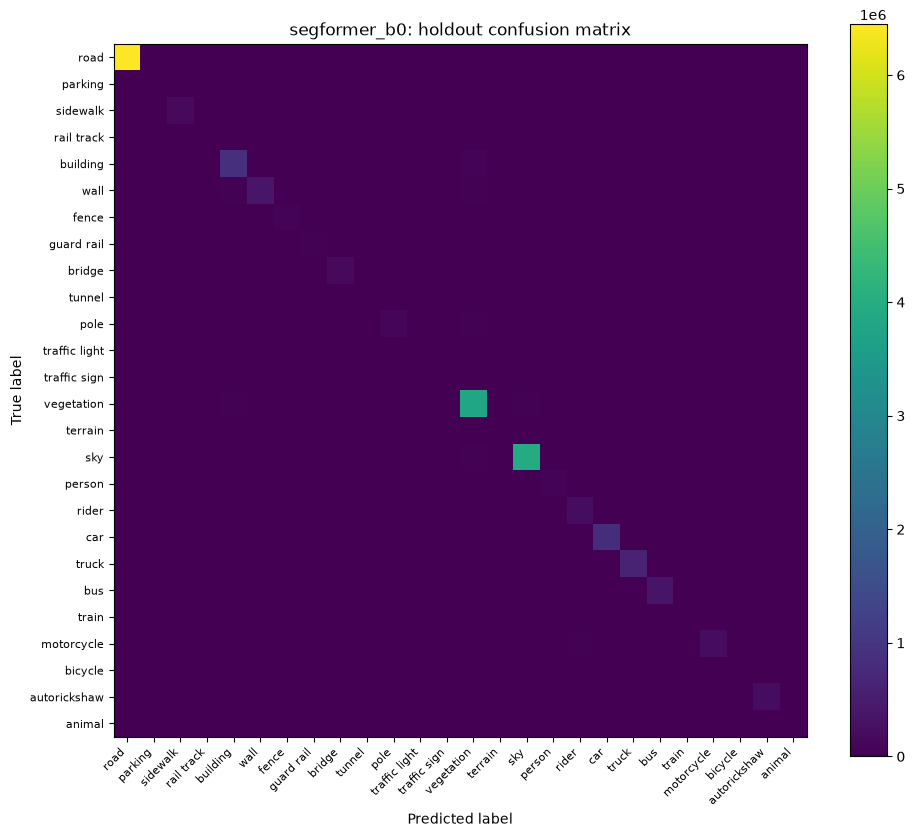

{
  "model": "segformer_b0",
  "holdout_count": 687,
  "holdout_loss": 0.16824644964508267,
  "pixel_accuracy": 0.9478503995290004,
  "macro_miou": 0.5391918717129314,
  "weighted_miou": 0.9059559767787186,
  "macro_precision": 0.6897645908407929,
  "macro_recall": 0.5993709376453306,
  "macro_f1": 0.6253514568793757,
  "weighted_f1": 0.9468055986071504,
  "balanced_accuracy": 0.7083474717626634
}

Per-class metrics:


,precision,recall,f1-score,support
road,0.9899,0.9914,0.9907,6.503957e+06
parking,0.0000,0.0000,0.0000,7.000000e+00
sidewalk,0.9140,0.8686,0.8907,1.955660e+05
rail track,0.0000,0.0000,0.0000,0.000000e+00
building,0.8479,0.8681,0.8579,1.010963e+06
wall,0.8618,0.7764,0.8169,4.951440e+05
fence,0.6250,0.5050,0.5586,1.030980e+05
guard rail,0.7633,0.6631,0.7097,4.011600e+04
bridge,0.8739,0.9246,0.8986,1.692290e+05
tunnel,0.0000,0.0000,0.0000,0.000000e+00


In [10]:
segformer_b0_metrics = run_one_model("segformer_b0")

Notice: GPU not detected. Running evaluation for segformer_b1 on CPU using saved checkpoints.


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Notice: GPU not detected. Skipping training function execution on CPU-only setup.


Evaluating segformer_b1:   0%|          | 0/172 [00:00<?, ?it/s]

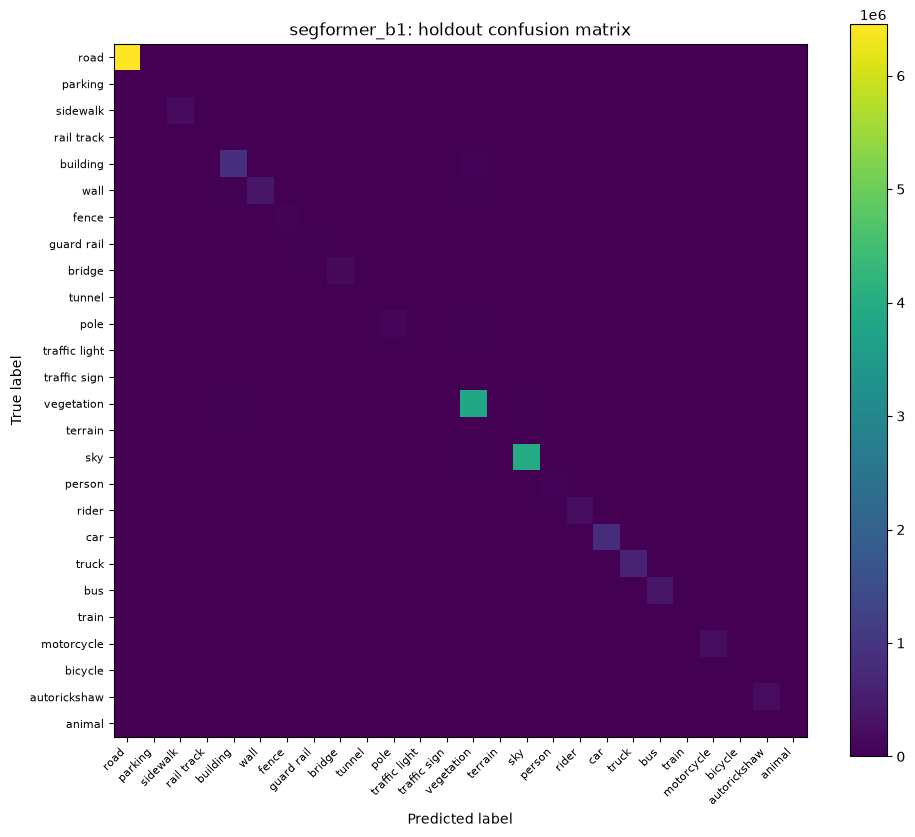

{
  "model": "segformer_b1",
  "holdout_count": 687,
  "holdout_loss": 0.1485825718924121,
  "pixel_accuracy": 0.955032753663108,
  "macro_miou": 0.5775401267299063,
  "weighted_miou": 0.9178696364350392,
  "macro_precision": 0.7072157849286005,
  "macro_recall": 0.6326516944323045,
  "macro_f1": 0.6582815869424155,
  "weighted_f1": 0.9543284229693106,
  "balanced_accuracy": 0.747679275238178
}

Per-class metrics:


,precision,recall,f1-score,support
road,0.9918,0.9924,0.9921,6.503957e+06
parking,0.0000,0.0000,0.0000,7.000000e+00
sidewalk,0.9146,0.9076,0.9111,1.955660e+05
rail track,0.0000,0.0000,0.0000,0.000000e+00
building,0.8663,0.8801,0.8731,1.010963e+06
wall,0.8823,0.8042,0.8415,4.951440e+05
fence,0.7038,0.5310,0.6053,1.030980e+05
guard rail,0.8073,0.7362,0.7702,4.011600e+04
bridge,0.9257,0.9417,0.9336,1.692290e+05
tunnel,0.0000,0.0000,0.0000,0.000000e+00


In [11]:
segformer_b1_metrics = run_one_model("segformer_b1")

In [12]:
# ==============================================================================
# CELL 12: FINAL RESEARCH REPORT & METRICS COMPARISON TABLES
# ==============================================================================
import pandas as pd
from IPython.display import display

print("=" * 70)
print(" FINAL RESEARCH METRICS REPORT (ACIIDS / IEEE FUZZ) ".center(70, "="))
print("=" * 70)

comparison_csv = OUTPUT_DIR / "model_comparison_progress.csv"

if comparison_csv.exists():
    # 1. Overall Metrics Comparison Table
    print("\nTABLE 1: OVERALL MODEL COMPARISON (SegFormer-B0 vs SegFormer-B1)")
    df_comp = pd.read_csv(comparison_csv)

    metric_cols = [
        "pixel_accuracy", "macro_miou", "weighted_miou",
        "macro_precision", "macro_recall", "macro_f1",
        "weighted_f1", "balanced_accuracy"
    ]

    df_formatted = df_comp.copy()
    for col in metric_cols:
        if col in df_formatted.columns:
            df_formatted[col] = (df_formatted[col] * 100).round(2).astype(str) + "%"

    columns_order = [
        "model", "macro_miou", "weighted_miou", "pixel_accuracy",
        "macro_f1", "weighted_f1", "holdout_loss"
    ]
    df_formatted = df_formatted[[c for c in columns_order if c in df_formatted.columns]]
    display(df_formatted)

    # 2. Class-wise F1-Score Breakdown Table
    print("\nTABLE 2: CLASS-WISE F1-SCORE COMPARISON (26 IDD LEVEL-3 CLASSES)")
    class_reports = {}
    for model_name in MODEL_ORDER:
        report_csv = OUTPUT_DIR / f"{model_name}_classification_report.csv"
        if report_csv.exists():
            df_rep = pd.read_csv(report_csv, index_col=0)
            df_classes = df_rep.drop(["accuracy", "macro avg", "weighted avg"], errors="ignore")
            class_reports[model_name] = df_classes["f1-score"].round(4)

    if class_reports:
        df_class_comp = pd.DataFrame(class_reports)
        if "segformer_b0" in df_class_comp.columns and "segformer_b1" in df_class_comp.columns:
            df_class_comp["B1_Improvement"] = (
                df_class_comp["segformer_b1"] - df_class_comp["segformer_b0"]
            ).round(4)

        display(df_class_comp)

        df_formatted.to_csv(OUTPUT_DIR / "FINAL_TABLE1_Overall_Metrics.csv", index=False)
        df_class_comp.to_csv(OUTPUT_DIR / "FINAL_TABLE2_Classwise_F1.csv")
        print(f"\n-> Publication tables saved to: {OUTPUT_DIR.resolve()}")
else:
    print("[WARNING] Comparison CSV not found. Run Cells 10 and 11 first.")

========= FINAL RESEARCH METRICS REPORT (ACIIDS / IEEE FUZZ) =========

TABLE 1: OVERALL MODEL COMPARISON (SegFormer-B0 vs SegFormer-B1)


,model,macro_miou,weighted_miou,pixel_accuracy,macro_f1,weighted_f1,holdout_loss
0,segformer_b0,53.92%,90.6%,94.79%,62.54%,94.68%,0.168246
1,segformer_b1,57.75%,91.79%,95.5%,65.83%,95.43%,0.148583



TABLE 2: CLASS-WISE F1-SCORE COMPARISON (26 IDD LEVEL-3 CLASSES)


,segformer_b0,segformer_b1,B1_Improvement
road,0.9907,0.9921,0.0014
parking,0.0000,0.0000,0.0000
sidewalk,0.8907,0.9111,0.0204
rail track,0.0000,0.0000,0.0000
building,0.8579,0.8731,0.0152
wall,0.8169,0.8415,0.0246
fence,0.5586,0.6053,0.0467
guard rail,0.7097,0.7702,0.0605
bridge,0.8986,0.9336,0.0350
tunnel,0.0000,0.0000,0.0000



-> Publication tables saved to: D:\IDD_Research\aciids2027_outputs


In [13]:
# ==============================================================================
# CELL 13: IDD TAXONOMIC HIERARCHY (L3=26 -> L2=16 -> L1=7) & PROJECTION MATRICES
# ==============================================================================
import numpy as np
import torch

# Level-1 Coarse Safety Groups (K1 = 7) - Paper Section 4.1 & Table 3
IDD_LEVEL1_NAMES = [
    "drivable",        # 0
    "non-drivable",    # 1
    "living-thing",    # 2
    "vehicles",        # 3
    "road-side-objs",  # 4
    "far-objects",     # 5
    "sky"              # 6
]

# Level-2 Intermediate Superclasses (K2 = 16) - Paper Section 4.1 & Table 3
IDD_LEVEL2_NAMES = [
    "road",                   # 0  -> L1: drivable
    "drivable-fallback",      # 1  -> L1: drivable
    "sidewalk",               # 2  -> L1: non-drivable
    "non-drivable-fallback",  # 3  -> L1: non-drivable
    "person-animal",          # 4  -> L1: living-thing
    "rider",                  # 5  -> L1: living-thing
    "2-wheeler",              # 6  -> L1: vehicles
    "small-vehicle",          # 7  -> L1: vehicles
    "large-vehicle",          # 8  -> L1: vehicles
    "curb-wall",              # 9  -> L1: road-side-objs
    "fence-guardrail",        # 10 -> L1: road-side-objs
    "traffic-device",         # 11 -> L1: road-side-objs
    "pole-obs-fallback",      # 12 -> L1: road-side-objs
    "construction",           # 13 -> L1: far-objects
    "vegetation",             # 14 -> L1: far-objects
    "sky"                     # 15 -> L1: sky
]

L1_IDX = {name: i for i, name in enumerate(IDD_LEVEL1_NAMES)}
L2_IDX = {name: i for i, name in enumerate(IDD_LEVEL2_NAMES)}

# Parent mapping from Level-2 (16) -> Level-1 (7)
L2_TO_L1_MAP = {
    "road": "drivable",
    "drivable-fallback": "drivable",
    "sidewalk": "non-drivable",
    "non-drivable-fallback": "non-drivable",
    "person-animal": "living-thing",
    "rider": "living-thing",
    "2-wheeler": "vehicles",
    "small-vehicle": "vehicles",
    "large-vehicle": "vehicles",
    "curb-wall": "road-side-objs",
    "fence-guardrail": "road-side-objs",
    "traffic-device": "road-side-objs",
    "pole-obs-fallback": "road-side-objs",
    "construction": "far-objects",
    "vegetation": "far-objects",
    "sky": "sky",
}

# Parent mapping from Level-3 (26 classes in Cell 4) -> Level-2 (16 superclasses)
L3_TO_L2_MAP = {
    "road": "road",
    "parking": "drivable-fallback",
    "drivable fallback": "drivable-fallback",
    "sidewalk": "sidewalk",
    "rail track": "non-drivable-fallback",
    "terrain": "non-drivable-fallback",
    "non-drivable fallback": "non-drivable-fallback",
    "person": "person-animal",
    "animal": "person-animal",
    "rider": "rider",
    "motorcycle": "2-wheeler",
    "bicycle": "2-wheeler",
    "autorickshaw": "small-vehicle",
    "car": "small-vehicle",
    "truck": "large-vehicle",
    "bus": "large-vehicle",
    "train": "large-vehicle",
    "vehicle fallback": "large-vehicle",
    "curb": "curb-wall",
    "wall": "curb-wall",
    "fence": "fence-guardrail",
    "guard rail": "fence-guardrail",
    "billboard": "traffic-device",
    "traffic sign": "traffic-device",
    "traffic light": "traffic-device",
    "pole": "pole-obs-fallback",
    "obs-str-bar-fallback": "pole-obs-fallback",
    "building": "construction",
    "bridge": "construction",
    "tunnel": "construction",
    "vegetation": "vegetation",
    "sky": "sky",
}

K3 = len(IDD_LEVEL3_NAMES) # 26
K2 = len(IDD_LEVEL2_NAMES) # 16
K1 = len(IDD_LEVEL1_NAMES) # 7

M_3to2_np = np.zeros((K3, K2), dtype=np.float32)
M_2to1_np = np.zeros((K2, K1), dtype=np.float32)

L3_TO_L2_ID = np.zeros(K3, dtype=np.int64)
L3_TO_L1_ID = np.zeros(K3, dtype=np.int64)

for j, l3_name in enumerate(IDD_LEVEL3_NAMES):
    l2_name = L3_TO_L2_MAP[l3_name]
    k = L2_IDX[l2_name]
    M_3to2_np[j, k] = 1.0
    L3_TO_L2_ID[j] = k

for k, l2_name in enumerate(IDD_LEVEL2_NAMES):
    l1_name = L2_TO_L1_MAP[l2_name]
    g = L1_IDX[l1_name]
    M_2to1_np[k, g] = 1.0

# Associative chain property: M_{3->1} = M_{3->2} @ M_{2->1} (Equation 2)
M_3to1_np = M_3to2_np @ M_2to1_np
for j in range(K3):
    L3_TO_L1_ID[j] = int(np.argmax(M_3to1_np[j]))

M_3to2 = torch.from_numpy(M_3to2_np).to(DEVICE)
M_2to1 = torch.from_numpy(M_2to1_np).to(DEVICE)
M_3to1 = torch.from_numpy(M_3to1_np).to(DEVICE)

# Shannon bit-specificity weights for HICS (Equation 10)
W3_HICS = float(np.log2(K3) / np.log2(K3))  # 1.0000
W2_HICS = float(np.log2(K2) / np.log2(K3))  # ~0.8510
W1_HICS = float(np.log2(K1) / np.log2(K3))  # ~0.5973

print(f"Projection matrices verified: M_3to2={M_3to2.shape}, M_3to1={M_3to1.shape}")
print(f"Row-sum check (must be 1.0): L3->L2={M_3to2_np.sum(axis=1).min()}, L3->L1={M_3to1_np.sum(axis=1).min()}")
print(f"HICS specificity weights: w3={W3_HICS:.3f}, w2={W2_HICS:.3f}, w1={W1_HICS:.3f}")

Projection matrices verified: M_3to2=torch.Size([26, 16]), M_3to1=torch.Size([26, 7])
Row-sum check (must be 1.0): L3->L2=1.0, L3->L1=1.0
HICS specificity weights: w3=1.000, w2=0.851, w1=0.597


In [14]:
# ==============================================================================
# CELL 14: JOINT HIERARCHY-CONSISTENT TEMPERATURE SCALING (TABLE 6)
# ==============================================================================
def compute_ece(confidences: np.ndarray, accuracies: np.ndarray, n_bins: int = 15) -> float:
    """Expected Calibration Error (ECE) in percentage (0-100%), Equation (6)."""
    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n_total = len(confidences)
    if n_total == 0:
        return 0.0
    for m in range(n_bins):
        in_bin = (confidences > bin_boundaries[m]) & (confidences <= bin_boundaries[m + 1])
        prop_in_bin = np.mean(in_bin)
        if prop_in_bin > 0:
            acc_in_bin = np.mean(accuracies[in_bin])
            conf_in_bin = np.mean(confidences[in_bin])
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
    return float(ece * 100.0)

def collect_calibration_logits(model_name: str, stride: int = 4):
    """Collect subsampled calibration logits and ground-truth labels on cal_loader."""
    model = build_model(model_name).to(DEVICE)
    best_path = best_checkpoint_path(model_name)
    if not best_path.exists():
        raise FileNotFoundError(f"Best checkpoint not found at {best_path}. Train {model_name} first.")
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    model.eval()

    logits_list, y3_list = [], []
    with torch.no_grad():
        for images, targets in tqdm(cal_loader, desc=f"Calibrating {model_name}"):
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                outputs = model(pixel_values=images)
                up_logits = F.interpolate(outputs.logits, size=targets.shape[-2:], mode="bilinear", align_corners=False)

            # Subsample spatial grid (stride x stride) for fast, exact ECE optimization
            sub_logits = up_logits[:, :, ::stride, ::stride].permute(0, 2, 3, 1).reshape(-1, K3)
            sub_targets = targets[:, ::stride, ::stride].reshape(-1)
            valid = (sub_targets != IGNORE_INDEX)

            logits_list.append(sub_logits[valid].float().cpu())
            y3_list.append(sub_targets[valid].cpu())

    del model
    torch.cuda.empty_cache()
    gc.collect()
    return torch.cat(logits_list, dim=0), torch.cat(y3_list, dim=0).numpy()

def evaluate_hierarchy_ece_at_T(logits_cpu: torch.Tensor, y3_true: np.ndarray, T: float, chunk_size: int = 250000):
    """Project scaled probabilities across L3, L2, L1 and compute ECE at each level."""
    y2_true = L3_TO_L2_ID[y3_true]
    y1_true = L3_TO_L1_ID[y3_true]

    N = len(y3_true)
    c3_all, a3_all = np.empty(N, dtype=np.float32), np.empty(N, dtype=np.float32)
    c2_all, a2_all = np.empty(N, dtype=np.float32), np.empty(N, dtype=np.float32)
    c1_all, a1_all = np.empty(N, dtype=np.float32), np.empty(N, dtype=np.float32)

    with torch.no_grad():
        for start in range(0, N, chunk_size):
            end = min(start + chunk_size, N)
            z = logits_cpu[start:end].to(DEVICE)
            p3 = torch.softmax(z / T, dim=-1)
            p2 = p3 @ M_3to2
            p1 = p3 @ M_3to1

            c3, pred3 = p3.max(dim=-1)
            c2, pred2 = p2.max(dim=-1)
            c1, pred1 = p1.max(dim=-1)

            c3_all[start:end] = c3.cpu().numpy()
            c2_all[start:end] = c2.cpu().numpy()
            c1_all[start:end] = c1.cpu().numpy()

            a3_all[start:end] = (pred3.cpu().numpy() == y3_true[start:end]).astype(np.float32)
            a2_all[start:end] = (pred2.cpu().numpy() == y2_true[start:end]).astype(np.float32)
            a1_all[start:end] = (pred1.cpu().numpy() == y1_true[start:end]).astype(np.float32)

    # Verify Proposition 1 (Monotonic Confidence Non-Decrease: c1 >= c2 >= c3)
    assert np.all(c1_all + 1e-5 >= c2_all) and np.all(c2_all + 1e-5 >= c3_all), "Hierarchy confidence monotonicity violated!"

    ece3 = compute_ece(c3_all, a3_all)
    ece2 = compute_ece(c2_all, a2_all)
    ece1 = compute_ece(c1_all, a1_all)
    return ece3, ece2, ece1

# Optimize T* over candidate grid [0.50, 2.50] (Equation 5)
T_GRID = np.round(np.arange(0.50, 2.525, 0.025), 3)
OPTIMAL_TEMPS = {}
table6_rows = []

for model_name in MODEL_ORDER:
    logits_cal, y3_cal = collect_calibration_logits(model_name, stride=4)
    uncal_ece3, uncal_ece2, uncal_ece1 = evaluate_hierarchy_ece_at_T(logits_cal, y3_cal, T=1.0)

    best_T = 1.0
    best_joint_ece = float("inf")
    best_eces = (uncal_ece3, uncal_ece2, uncal_ece1)

    for T_cand in tqdm(T_GRID, desc=f"Grid search T* for {model_name}", leave=False):
        e3, e2, e1 = evaluate_hierarchy_ece_at_T(logits_cal, y3_cal, T=float(T_cand))
        joint_ece = e3 + e2 + e1
        if joint_ece < best_joint_ece:
            best_joint_ece = joint_ece
            best_T = float(T_cand)
            best_eces = (e3, e2, e1)

    OPTIMAL_TEMPS[model_name] = best_T
    cal_ece3, cal_ece2, cal_ece1 = best_eces

    for level_str, u_ece, c_ece in [
        ("Level 3 (26 Classes)", uncal_ece3, cal_ece3),
        ("Level 2 (16 Classes)", uncal_ece2, cal_ece2),
        ("Level 1 (7 Groups)",   uncal_ece1, cal_ece1),
    ]:
        rel_drop = ((c_ece - u_ece) / max(u_ece, 1e-6)) * 100.0
        table6_rows.append({
            "Backbone": "SegFormer-B0" if "b0" in model_name else "SegFormer-B1",
            "Hierarchy Level": level_str,
            "T*": f"{best_T:.3f}",
            "Uncal. ECE (%)": f"{u_ece:.2f}%",
            "Cal. ECE (%)": f"{c_ece:.2f}%",
            "Rel. Drop": f"{rel_drop:+.1f}%"
        })

    del logits_cal, y3_cal
    gc.collect()

df_table6 = pd.DataFrame(table6_rows)
df_table6.to_csv(OUTPUT_DIR / "FINAL_PAPER_TABLE6_ECE_Calibration.csv", index=False)
with open(OUTPUT_DIR / "optimal_temperatures.json", "w") as f:
    json.dump(OPTIMAL_TEMPS, f, indent=2)

print("\n=== TABLE 6: EXPECTED CALIBRATION ERROR (ECE %) BEFORE & AFTER JOINT TEMPERATURE SCALING ===")
display(df_table6)

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Calibrating segformer_b0:   0%|          | 0/74 [00:00<?, ?it/s]

Grid search T* for segformer_b0:   0%|          | 0/81 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Calibrating segformer_b1:   0%|          | 0/74 [00:00<?, ?it/s]

Grid search T* for segformer_b1:   0%|          | 0/81 [00:00<?, ?it/s]


=== TABLE 6: EXPECTED CALIBRATION ERROR (ECE %) BEFORE & AFTER JOINT TEMPERATURE SCALING ===


,Backbone,Hierarchy Level,T*,Uncal. ECE (%),Cal. ECE (%),Rel. Drop
0,SegFormer-B0,Level 3 (26 Classes),1.250,1.26%,0.23%,-81.4%
1,SegFormer-B0,Level 2 (16 Classes),1.250,1.21%,0.21%,-82.7%
2,SegFormer-B0,Level 1 (7 Groups),1.250,0.85%,0.13%,-84.7%
3,SegFormer-B1,Level 3 (26 Classes),1.250,1.04%,0.18%,-82.5%
4,SegFormer-B1,Level 2 (16 Classes),1.250,1.00%,0.18%,-82.5%
5,SegFormer-B1,Level 1 (7 Groups),1.250,0.66%,0.15%,-77.0%


In [15]:
# ==============================================================================
# CELL 15: CHSF EVALUATION ON HOLDOUT SPLIT (TABLES 5, 7, 8, 9 & SWEEP DATA)
# ==============================================================================
SWEEP_TAU3 = [0.35, 0.45, 0.55, 0.65, 0.75]
REF_TAU3 = 0.55
DRIVABLE_L1_ID = L1_IDX["drivable"] # 0

def get_tau_schedule(tau3: float):
    """Equation (8): Relative hierarchical threshold offsets."""
    tau2 = max(0.30, round(tau3 - 0.05, 2))
    tau1 = min(0.90, round(tau3 + 0.05, 2))
    return round(tau3, 2), tau2, tau1

def compute_kept_l3_miou(y3_true: np.ndarray, y3_pred: np.ndarray, kept_mask: np.ndarray) -> float:
    """Equation (9): Kept Level-3 mIoU (%) over pixels retained at Level 3."""
    if np.sum(kept_mask) == 0:
        return 0.0
    yt = y3_true[kept_mask]
    yp = y3_pred[kept_mask]
    ious = []
    for k in range(K3):
        inter = np.sum((yp == k) & (yt == k))
        union = np.sum((yp == k) | (yt == k))
        if union > 0:
            ious.append(inter / union)
    return float(np.mean(ious) * 100.0) if ious else 0.0

def evaluate_chsf_on_holdout(model_name: str, T_star: float, stride: int = 4):
    """Run full holdout evaluation for Plain Baseline, Abstain Ignore, and Proposed CHSF."""
    model = build_model(model_name).to(DEVICE)
    best_path = best_checkpoint_path(model_name)
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    model.eval()

    y3_true_list = []
    pred3_list, pred2_list, pred1_list = [], [], []
    c3_list, c2_list, c1_list = [], [], []
    c3_uncal_list = []

    with torch.no_grad():
        for images, targets in tqdm(holdout_loader, desc=f"CHSF Holdout Eval ({model_name})"):
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                outputs = model(pixel_values=images)
                up_logits = F.interpolate(outputs.logits, size=targets.shape[-2:], mode="bilinear", align_corners=False)

            sub_logits = up_logits[:, :, ::stride, ::stride].permute(0, 2, 3, 1).reshape(-1, K3)
            sub_targets = targets[:, ::stride, ::stride].reshape(-1)
            valid = (sub_targets != IGNORE_INDEX)

            z = sub_logits[valid].float()
            y_valid = sub_targets[valid]

            # Uncalibrated L3 confidence
            p3_uncal = torch.softmax(z, dim=-1)
            c3_u, _ = p3_uncal.max(dim=-1)

            # Calibrated probabilities across L3, L2, L1 (Equations 1 & 2)
            p3 = torch.softmax(z / T_star, dim=-1)
            p2 = p3 @ M_3to2
            p1 = p3 @ M_3to1

            c3, p_l3 = p3.max(dim=-1)
            c2, p_l2 = p2.max(dim=-1)
            c1, p_l1 = p1.max(dim=-1)

            y3_true_list.append(y_valid.cpu().numpy())
            pred3_list.append(p_l3.cpu().numpy())
            pred2_list.append(p_l2.cpu().numpy())
            pred1_list.append(p_l1.cpu().numpy())
            c3_list.append(c3.cpu().numpy())
            c2_list.append(c2.cpu().numpy())
            c1_list.append(c1.cpu().numpy())
            c3_uncal_list.append(c3_u.cpu().numpy())

    del model
    torch.cuda.empty_cache()
    gc.collect()

    y3_true = np.concatenate(y3_true_list)
    y2_true = L3_TO_L2_ID[y3_true]
    y1_true = L3_TO_L1_ID[y3_true]

    pred3 = np.concatenate(pred3_list)
    pred2 = np.concatenate(pred2_list)
    pred1 = np.concatenate(pred1_list)

    c3 = np.concatenate(c3_list)
    c2 = np.concatenate(c2_list)
    c1 = np.concatenate(c1_list)

    N_valid = len(y3_true)
    non_drive_mask = (y1_true != DRIVABLE_L1_ID)
    N_non_drive = int(np.sum(non_drive_mask))

    # Map L3 predictions to their corresponding L1 group for Plain/Abstain SCMR & FDR
    pred3_as_l1 = L3_TO_L1_ID[pred3]

    # 1. Plain Baseline Metrics (100% coverage, forces L3 argmax everywhere)
    plain_miou = compute_kept_l3_miou(y3_true, pred3, np.ones(N_valid, dtype=bool))
    plain_hics = float(np.mean(pred3 == y3_true) * W3_HICS * 100.0)
    plain_scmr = float(np.mean(pred3_as_l1 != y1_true) * 100.0)
    plain_fdr  = float(np.mean(pred3_as_l1[non_drive_mask] == DRIVABLE_L1_ID) * 100.0)

    sweep_records = []
    class_audit_rows = []

    for tau3 in SWEEP_TAU3:
        tau3, tau2, tau1 = get_tau_schedule(tau3)

        # Hierarchy assignment rules (Equation 7)
        keep_l3 = (c3 >= tau3)
        fall_l2 = (~keep_l3) & (c2 >= tau2)
        fall_l1 = (~keep_l3) & (~fall_l2) & (c1 >= tau1)
        active_chsf = keep_l3 | fall_l2 | fall_l1

        cov_l3 = float(np.mean(keep_l3) * 100.0)
        cov_l2 = float(np.mean(fall_l2) * 100.0)
        cov_l1 = float(np.mean(fall_l1) * 100.0)
        cov_fallback = cov_l2 + cov_l1
        cov_total = cov_l3 + cov_fallback

        # Kept L3 mIoU (same for Abstain Ignore and CHSF at a given tau3)
        kept_miou = compute_kept_l3_miou(y3_true, pred3, keep_l3)

        # HICS (Equation 10)
        hics_abstain = float(np.mean(keep_l3 & (pred3 == y3_true)) * W3_HICS * 100.0)
        hics_chsf = float((
            np.sum(keep_l3 & (pred3 == y3_true)) * W3_HICS +
            np.sum(fall_l2 & (pred2 == y2_true)) * W2_HICS +
            np.sum(fall_l1 & (pred1 == y1_true)) * W1_HICS
        ) / N_valid * 100.0)

        # Effective Level-1 group assigned to each active pixel for SCMR & FDR (Equations 11 & 12)
        active_l1_pred = np.full(N_valid, -1, dtype=np.int64)
        active_l1_pred[keep_l3] = pred3_as_l1[keep_l3]
        active_l1_pred[fall_l2] = np.argmax(M_2to1_np[pred2[fall_l2]], axis=-1)
        active_l1_pred[fall_l1] = pred1[fall_l1]

        scmr_abstain = float(np.mean(keep_l3 & (pred3_as_l1 != y1_true)) * 100.0)
        fdr_abstain  = float(np.mean(keep_l3[non_drive_mask] & (pred3_as_l1[non_drive_mask] == DRIVABLE_L1_ID)) * 100.0)

        scmr_chsf = float(np.mean(active_chsf & (active_l1_pred != y1_true)) * 100.0)
        fdr_chsf  = float(np.mean(active_chsf[non_drive_mask] & (active_l1_pred[non_drive_mask] == DRIVABLE_L1_ID)) * 100.0)

        sweep_records.append({
            "model": model_name,
            "tau3": tau3, "tau2": tau2, "tau1": tau1,
            "plain_coverage": 100.0, "plain_hics": plain_hics, "plain_miou": plain_miou,
            "plain_scmr": plain_scmr, "plain_fdr": plain_fdr,
            "abstain_coverage": cov_l3, "abstain_hics": hics_abstain, "abstain_miou": kept_miou,
            "abstain_scmr": scmr_abstain, "abstain_fdr": fdr_abstain,
            "chsf_l3_kept": cov_l3, "chsf_l2_fall": cov_l2, "chsf_l1_fall": cov_l1,
            "chsf_fallback_total": cov_fallback, "chsf_total_coverage": cov_total,
            "chsf_hics": hics_chsf, "chsf_miou": kept_miou,
            "chsf_scmr": scmr_chsf, "chsf_fdr": fdr_chsf,
        })

        # Table 9: Class-wise ambiguity audit at reference threshold tau3 = 0.55
        if abs(tau3 - REF_TAU3) < 1e-5 and "b1" in model_name:
            for c_id, c_name in enumerate(IDD_LEVEL3_NAMES):
                cls_mask = (y3_true == c_id)
                cls_pixels = int(np.sum(cls_mask))
                if cls_pixels > 0:
                    fb_rate = float(np.mean(fall_l2[cls_mask] | fall_l1[cls_mask]) * 100.0)
                    l2_super = L3_TO_L2_MAP[c_name]
                    l1_group = L2_TO_L1_MAP[l2_super]
                    class_audit_rows.append({
                        "Level-3 Class": c_name,
                        "Level-2 Superclass": l2_super,
                        "Level-1 Group": l1_group,
                        "Pixels": cls_pixels,
                        "Fallback (%)": fb_rate
                    })

    return sweep_records, class_audit_rows

all_sweep_rows = []
table9_audit = []

for m_name in MODEL_ORDER:
    T_val = OPTIMAL_TEMPS.get(m_name, 1.0)
    s_rows, c_audit = evaluate_chsf_on_holdout(m_name, T_star=T_val, stride=4)
    all_sweep_rows.extend(s_rows)
    if c_audit:
        table9_audit = c_audit

df_sweep = pd.DataFrame(all_sweep_rows)
df_sweep.to_csv(OUTPUT_DIR / "FINAL_PAPER_SWEEP_ALL_THRESHOLDS.csv", index=False)

# --- Build Table 7 & Table 8 at Reference Threshold tau3 = 0.55 ---
table7_rows, table8_rows = [], []
for _, row in df_sweep[df_sweep["tau3"] == REF_TAU3].iterrows():
    b_label = "SegFormer-B0" if "b0" in row["model"] else "SegFormer-B1"
    # Table 7: Coverage and HICS
    table7_rows.extend([
        {"Backbone": b_label, "Method": "Plain Baseline",        "L2+L1 Fallback": "0.00%",                            "Total Coverage": "100.00%",                          "HICS": f"{row['plain_hics']:.2f}%"},
        {"Backbone": b_label, "Method": "Abstain Ignore",        "L2+L1 Fallback": "0.00%",                            "Total Coverage": f"{row['abstain_coverage']:.2f}%",  "HICS": f"{row['abstain_hics']:.2f}%"},
        {"Backbone": b_label, "Method": "Hierarchical Fallback", "L2+L1 Fallback": f"{row['chsf_fallback_total']:.2f}%", "Total Coverage": f"{row['chsf_total_coverage']:.2f}%", "HICS": f"{row['chsf_hics']:.2f}%"},
    ])
    # Table 8: Kept L3 mIoU, SCMR, FDR
    table8_rows.extend([
        {"Backbone": b_label, "Method": "Plain Baseline",        "Kept L3 mIoU": f"{row['plain_miou']:.2f}%",   "SCMR": f"{row['plain_scmr']:.2f}%",   "FDR": f"{row['plain_fdr']:.2f}%"},
        {"Backbone": b_label, "Method": "Abstain Ignore",        "Kept L3 mIoU": f"{row['abstain_miou']:.2f}%", "SCMR": f"{row['abstain_scmr']:.2f}%", "FDR": f"{row['abstain_fdr']:.2f}%"},
        {"Backbone": b_label, "Method": "Hierarchical Fallback", "Kept L3 mIoU": f"{row['chsf_miou']:.2f}%",    "SCMR": f"{row['chsf_scmr']:.2f}%",    "FDR": f"{row['chsf_fdr']:.2f}%"},
    ])

df_table7 = pd.DataFrame(table7_rows)
df_table8 = pd.DataFrame(table8_rows)
df_table7.to_csv(OUTPUT_DIR / "FINAL_PAPER_TABLE7_Coverage_HICS_tau055.csv", index=False)
df_table8.to_csv(OUTPUT_DIR / "FINAL_PAPER_TABLE8_Safety_Metrics_tau055.csv", index=False)

print("\n=== TABLE 7: COVERAGE & SEMANTIC INFORMATION RETENTION (tau3 = 0.55) ===")
display(df_table7)

print("\n=== TABLE 8: FINE-GRAINED ACCURACY & SAFETY-CRITICAL ERROR METRICS (tau3 = 0.55) ===")
display(df_table8)

if table9_audit:
    df_table9 = pd.DataFrame(table9_audit).sort_values(by="Fallback (%)", ascending=False).head(10).copy()
    df_table9["Fallback (%)"] = df_table9["Fallback (%)"].map(lambda x: f"{x:.2f}%")
    df_table9.to_csv(OUTPUT_DIR / "FINAL_PAPER_TABLE9_Ambiguity_Audit_Top10.csv", index=False)
    print("\n=== TABLE 9: TOP 10 LEVEL-3 CLASSES BY FALLBACK TRIGGER RATE (SegFormer-B1, tau3 = 0.55) ===")
    display(df_table9)

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

CHSF Holdout Eval (segformer_b0):   0%|          | 0/172 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

CHSF Holdout Eval (segformer_b1):   0%|          | 0/172 [00:00<?, ?it/s]


=== TABLE 7: COVERAGE & SEMANTIC INFORMATION RETENTION (tau3 = 0.55) ===


,Backbone,Method,L2+L1 Fallback,Total Coverage,HICS
0,SegFormer-B0,Plain Baseline,0.00%,100.00%,94.79%
1,SegFormer-B0,Abstain Ignore,0.00%,96.42%,93.13%
2,SegFormer-B0,Hierarchical Fallback,2.04%,98.46%,94.09%
3,SegFormer-B1,Plain Baseline,0.00%,100.00%,95.50%
4,SegFormer-B1,Abstain Ignore,0.00%,97.20%,94.19%
5,SegFormer-B1,Hierarchical Fallback,1.65%,98.85%,94.96%



=== TABLE 8: FINE-GRAINED ACCURACY & SAFETY-CRITICAL ERROR METRICS (tau3 = 0.55) ===


,Backbone,Method,Kept L3 mIoU,SCMR,FDR
0,SegFormer-B0,Plain Baseline,63.72%,3.88%,0.51%
1,SegFormer-B0,Abstain Ignore,70.02%,2.44%,0.36%
2,SegFormer-B0,Hierarchical Fallback,70.02%,3.08%,0.41%
3,SegFormer-B1,Plain Baseline,68.25%,3.33%,0.41%
4,SegFormer-B1,Abstain Ignore,73.65%,2.21%,0.30%
5,SegFormer-B1,Hierarchical Fallback,73.65%,2.73%,0.34%



=== TABLE 9: TOP 10 LEVEL-3 CLASSES BY FALLBACK TRIGGER RATE (SegFormer-B1, tau3 = 0.55) ===


,Level-3 Class,Level-2 Superclass,Level-1 Group,Pixels,Fallback (%)
9,traffic light,traffic-device,road-side-objs,2953,19.91%
1,parking,drivable-fallback,drivable,7,14.29%
19,bicycle,2-wheeler,vehicles,3467,13.35%
21,animal,person-animal,living-thing,1033,11.71%
8,pole,pole-obs-fallback,road-side-objs,197863,11.43%
5,fence,fence-guardrail,road-side-objs,103098,10.43%
13,person,person-animal,living-thing,96560,8.49%
6,guard rail,fence-guardrail,road-side-objs,40116,8.47%
18,motorcycle,2-wheeler,vehicles,266188,6.08%
14,rider,rider,living-thing,250840,5.84%


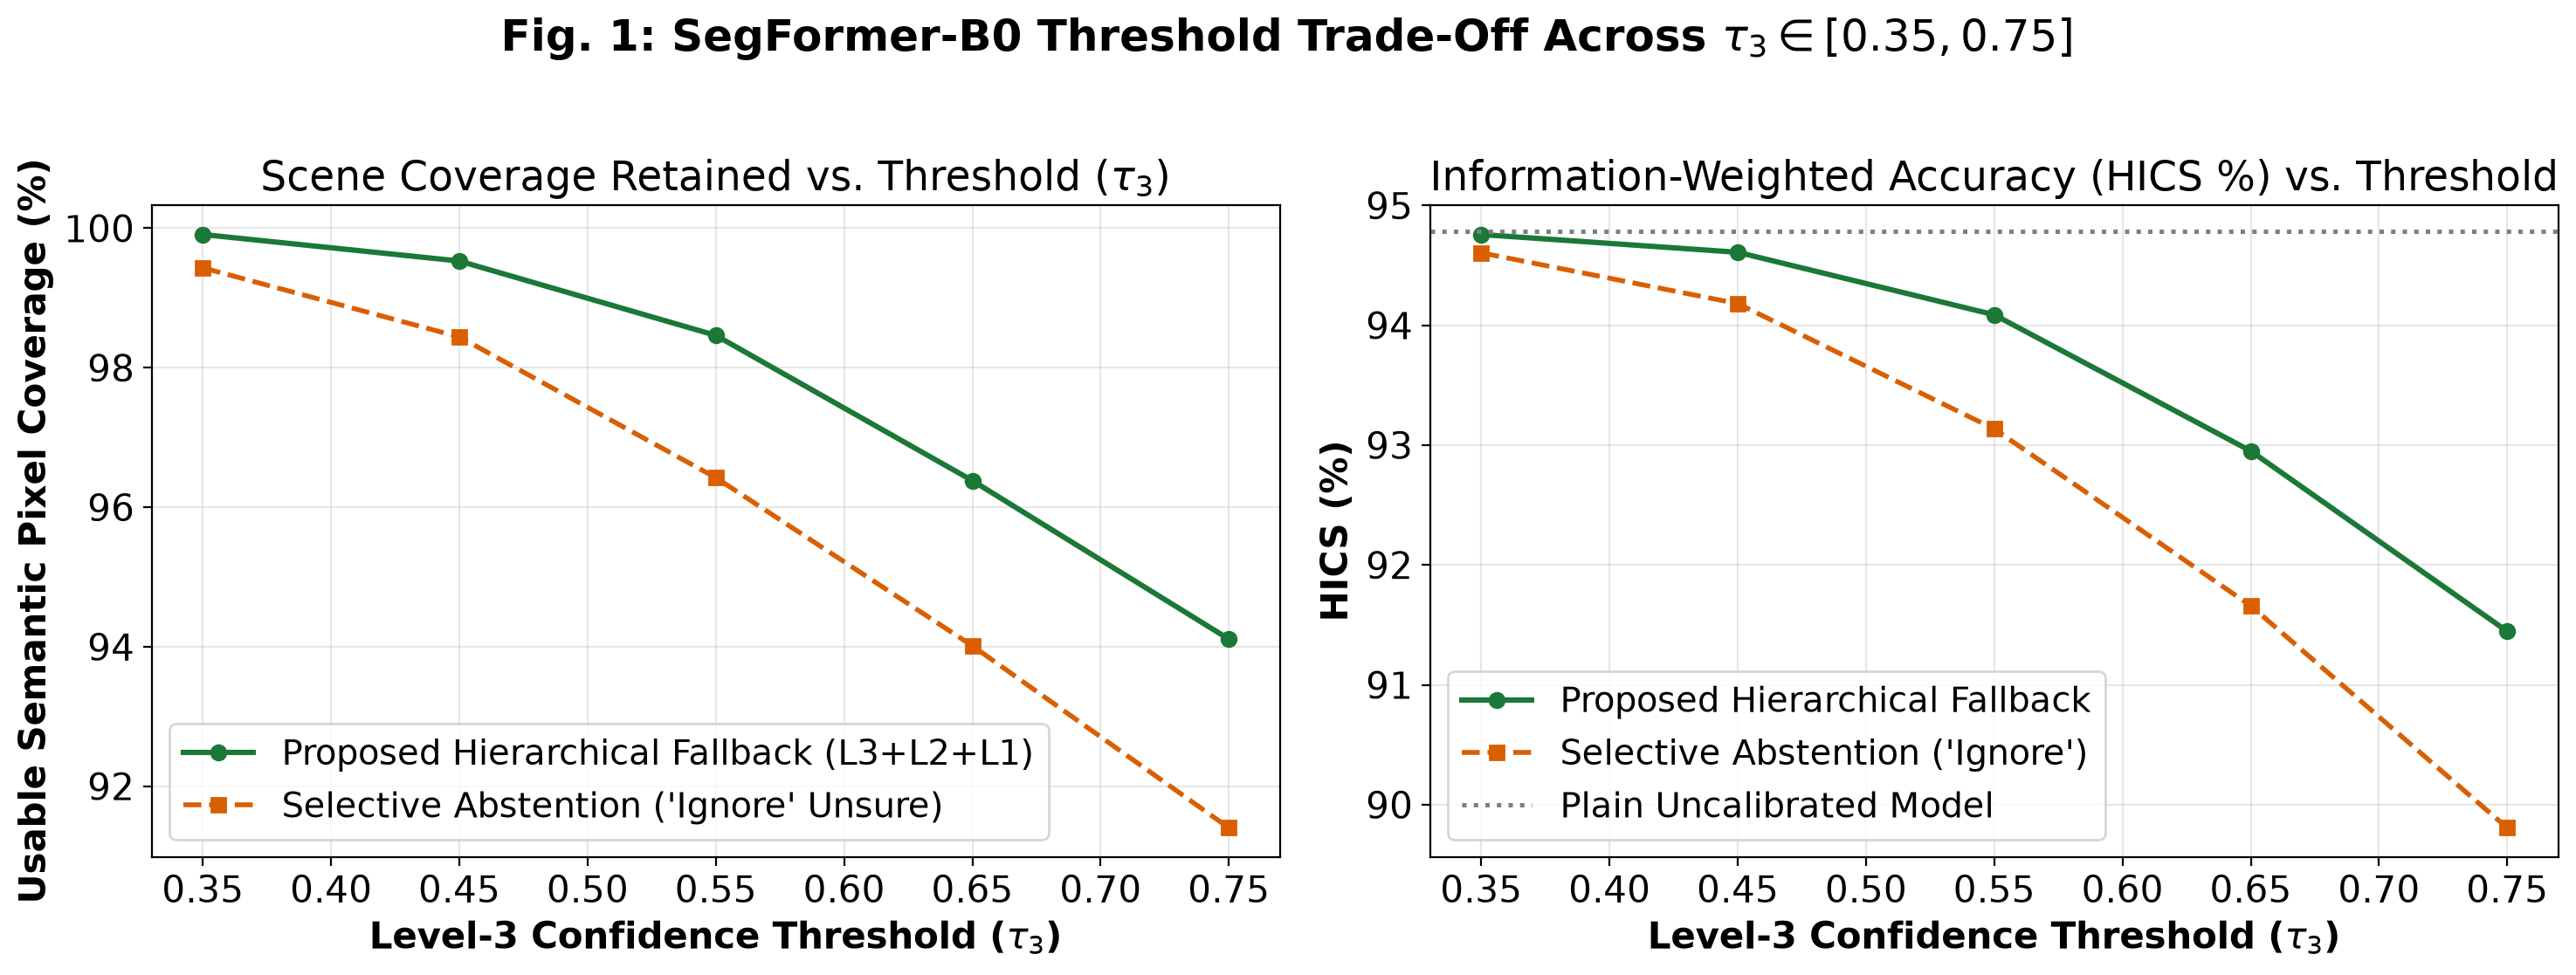

Saved publication figure: D:\IDD_Research\aciids2027_outputs\figures\Fig1_segformer_b0_CHSF_Tradeoff.png


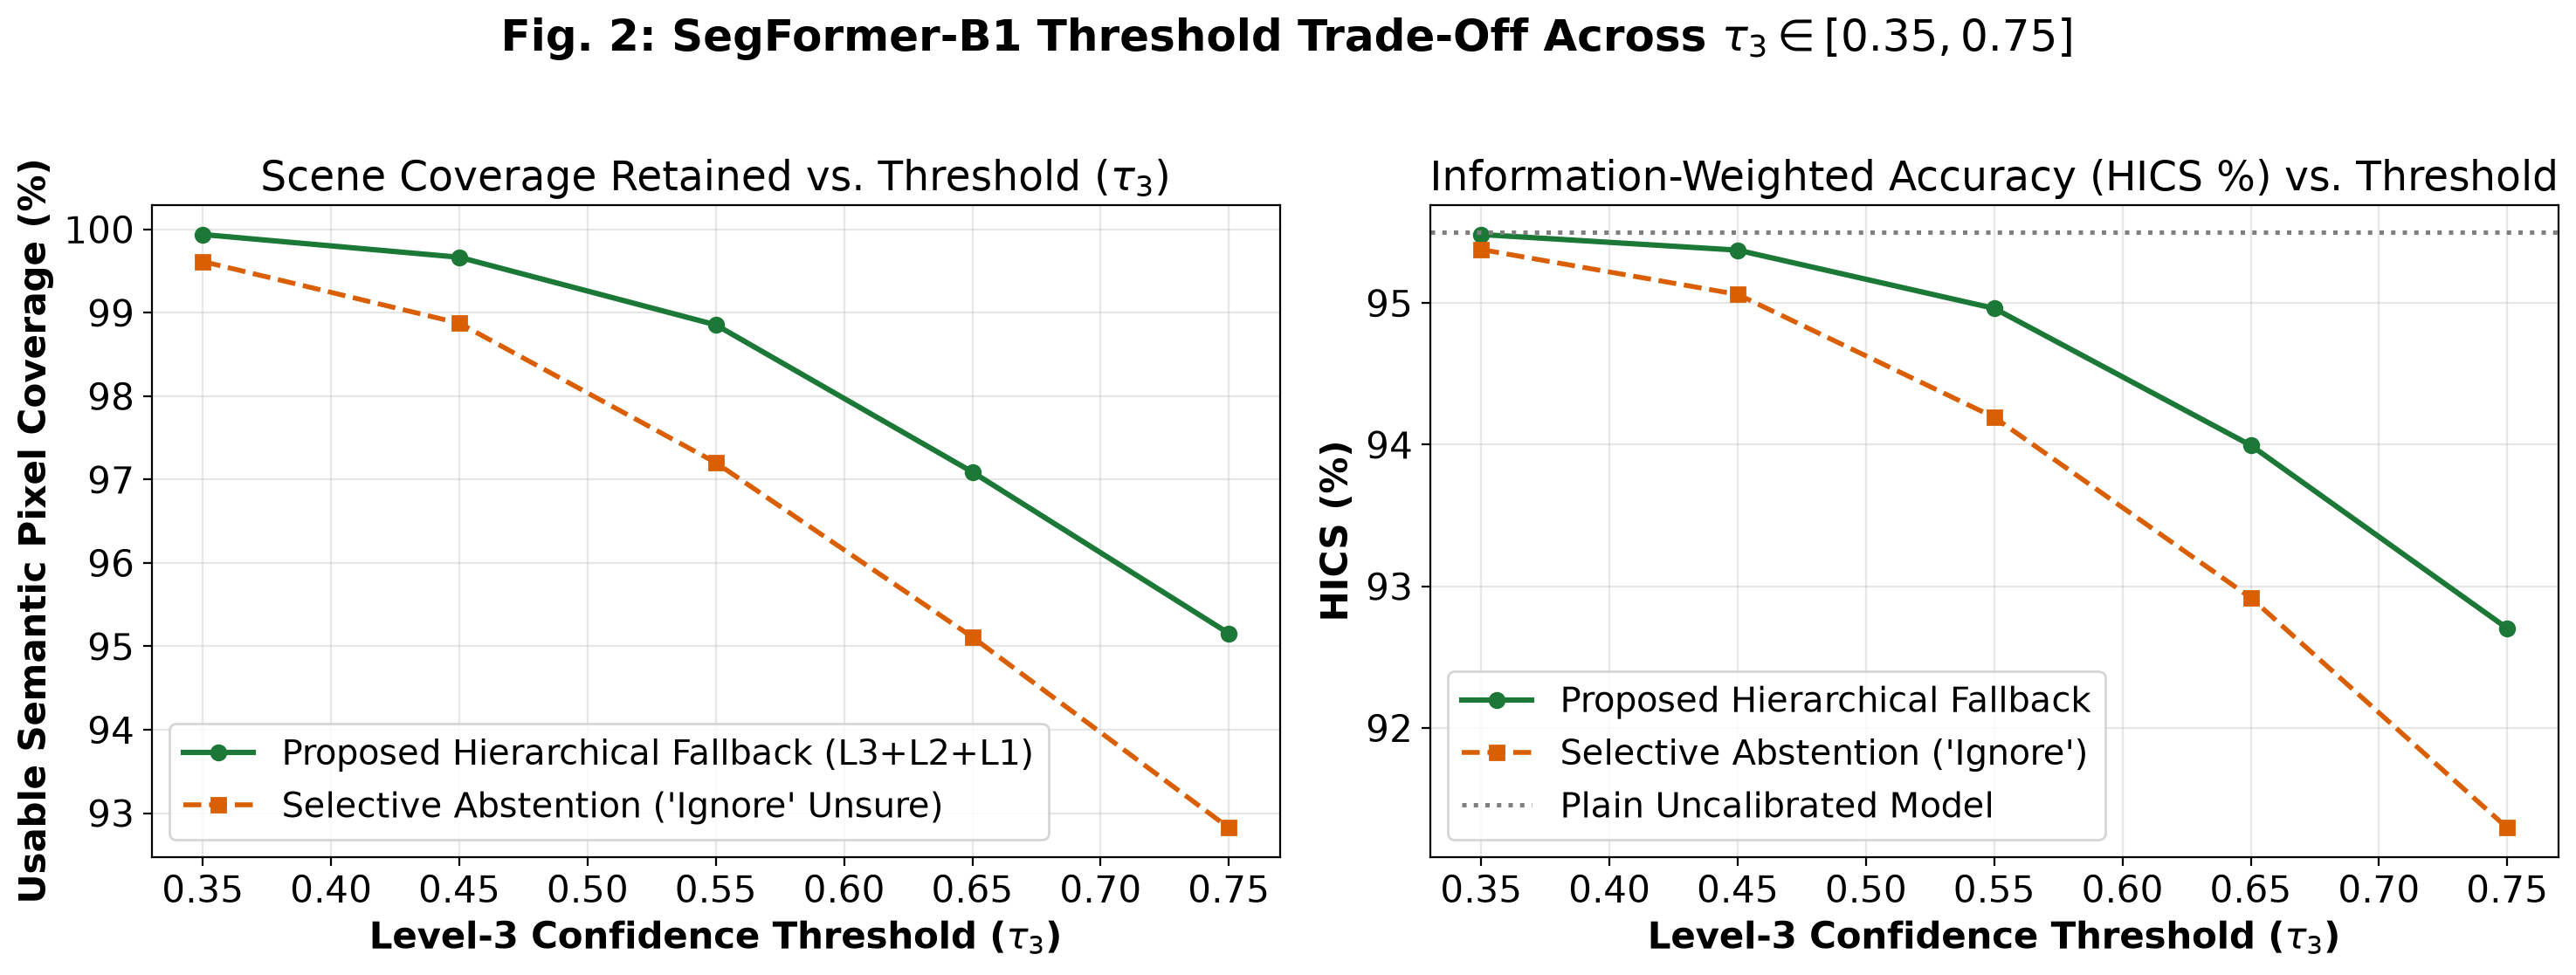

Saved publication figure: D:\IDD_Research\aciids2027_outputs\figures\Fig2_segformer_b1_CHSF_Tradeoff.png


In [46]:
# ==============================================================================
# CELL 16: THRESHOLD TRADE-OFF CURVES (FIGURES 1 & 2 IN PAPER)
# ==============================================================================
# Publication-quality font settings
plt.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 14.5,
    "figure.titlesize": 18
})
for idx, model_name in enumerate(MODEL_ORDER, start=1):
    sub = df_sweep[df_sweep["model"] == model_name].sort_values("tau3")
    if sub.empty:
        continue

    pretty_name = "SegFormer-B0" if "b0" in model_name else "SegFormer-B1"
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=200)

    # Panel A: Usable Semantic Pixel Coverage vs. Threshold (tau3)
    axes[0].plot(sub["tau3"], sub["chsf_total_coverage"], marker="o", linewidth=2.2, color="#1b7837",
                 label="Proposed Hierarchical Fallback (L3+L2+L1)")
    axes[0].plot(sub["tau3"], sub["abstain_coverage"], marker="s", linestyle="--", linewidth=2.0, color="#d95f02",
                 label="Selective Abstention ('Ignore' Unsure)")
    axes[0].set_title("Scene Coverage Retained vs. Threshold ($\\tau_3$)")
    axes[0].set_xlabel("Level-3 Confidence Threshold ($\\tau_3$)", fontweight="bold")
    axes[0].set_ylabel("Usable Semantic Pixel Coverage (%)", fontweight="bold")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc="best")

    # Panel B: Information-Weighted Accuracy (HICS %) vs. Threshold (tau3)
    axes[1].plot(sub["tau3"], sub["chsf_hics"], marker="o", linewidth=2.2, color="#1b7837",
                 label="Proposed Hierarchical Fallback")
    axes[1].plot(sub["tau3"], sub["abstain_hics"], marker="s", linestyle="--", linewidth=2.0, color="#d95f02",
                 label="Selective Abstention ('Ignore')")
    axes[1].axhline(y=float(sub["plain_hics"].iloc[0]), linestyle=":", linewidth=1.8, color="#7f7f7f",
                    label="Plain Uncalibrated Model")
    axes[1].set_title("Information-Weighted Accuracy (HICS %) vs. Threshold")
    axes[1].set_xlabel("Level-3 Confidence Threshold ($\\tau_3$)", fontweight="bold")
    axes[1].set_ylabel("HICS (%)", fontweight="bold")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(loc="best")

    fig.suptitle(f"Fig. {idx}: {pretty_name} Threshold Trade-Off Across $\\tau_3 \\in [0.35, 0.75]$", fontweight="bold", y=1.02)
    fig.tight_layout()
    out_fig = FIGURE_DIR / f"Fig{idx}_{model_name}_CHSF_Tradeoff.png"
    fig.savefig(out_fig, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved publication figure: {out_fig.resolve()}")

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

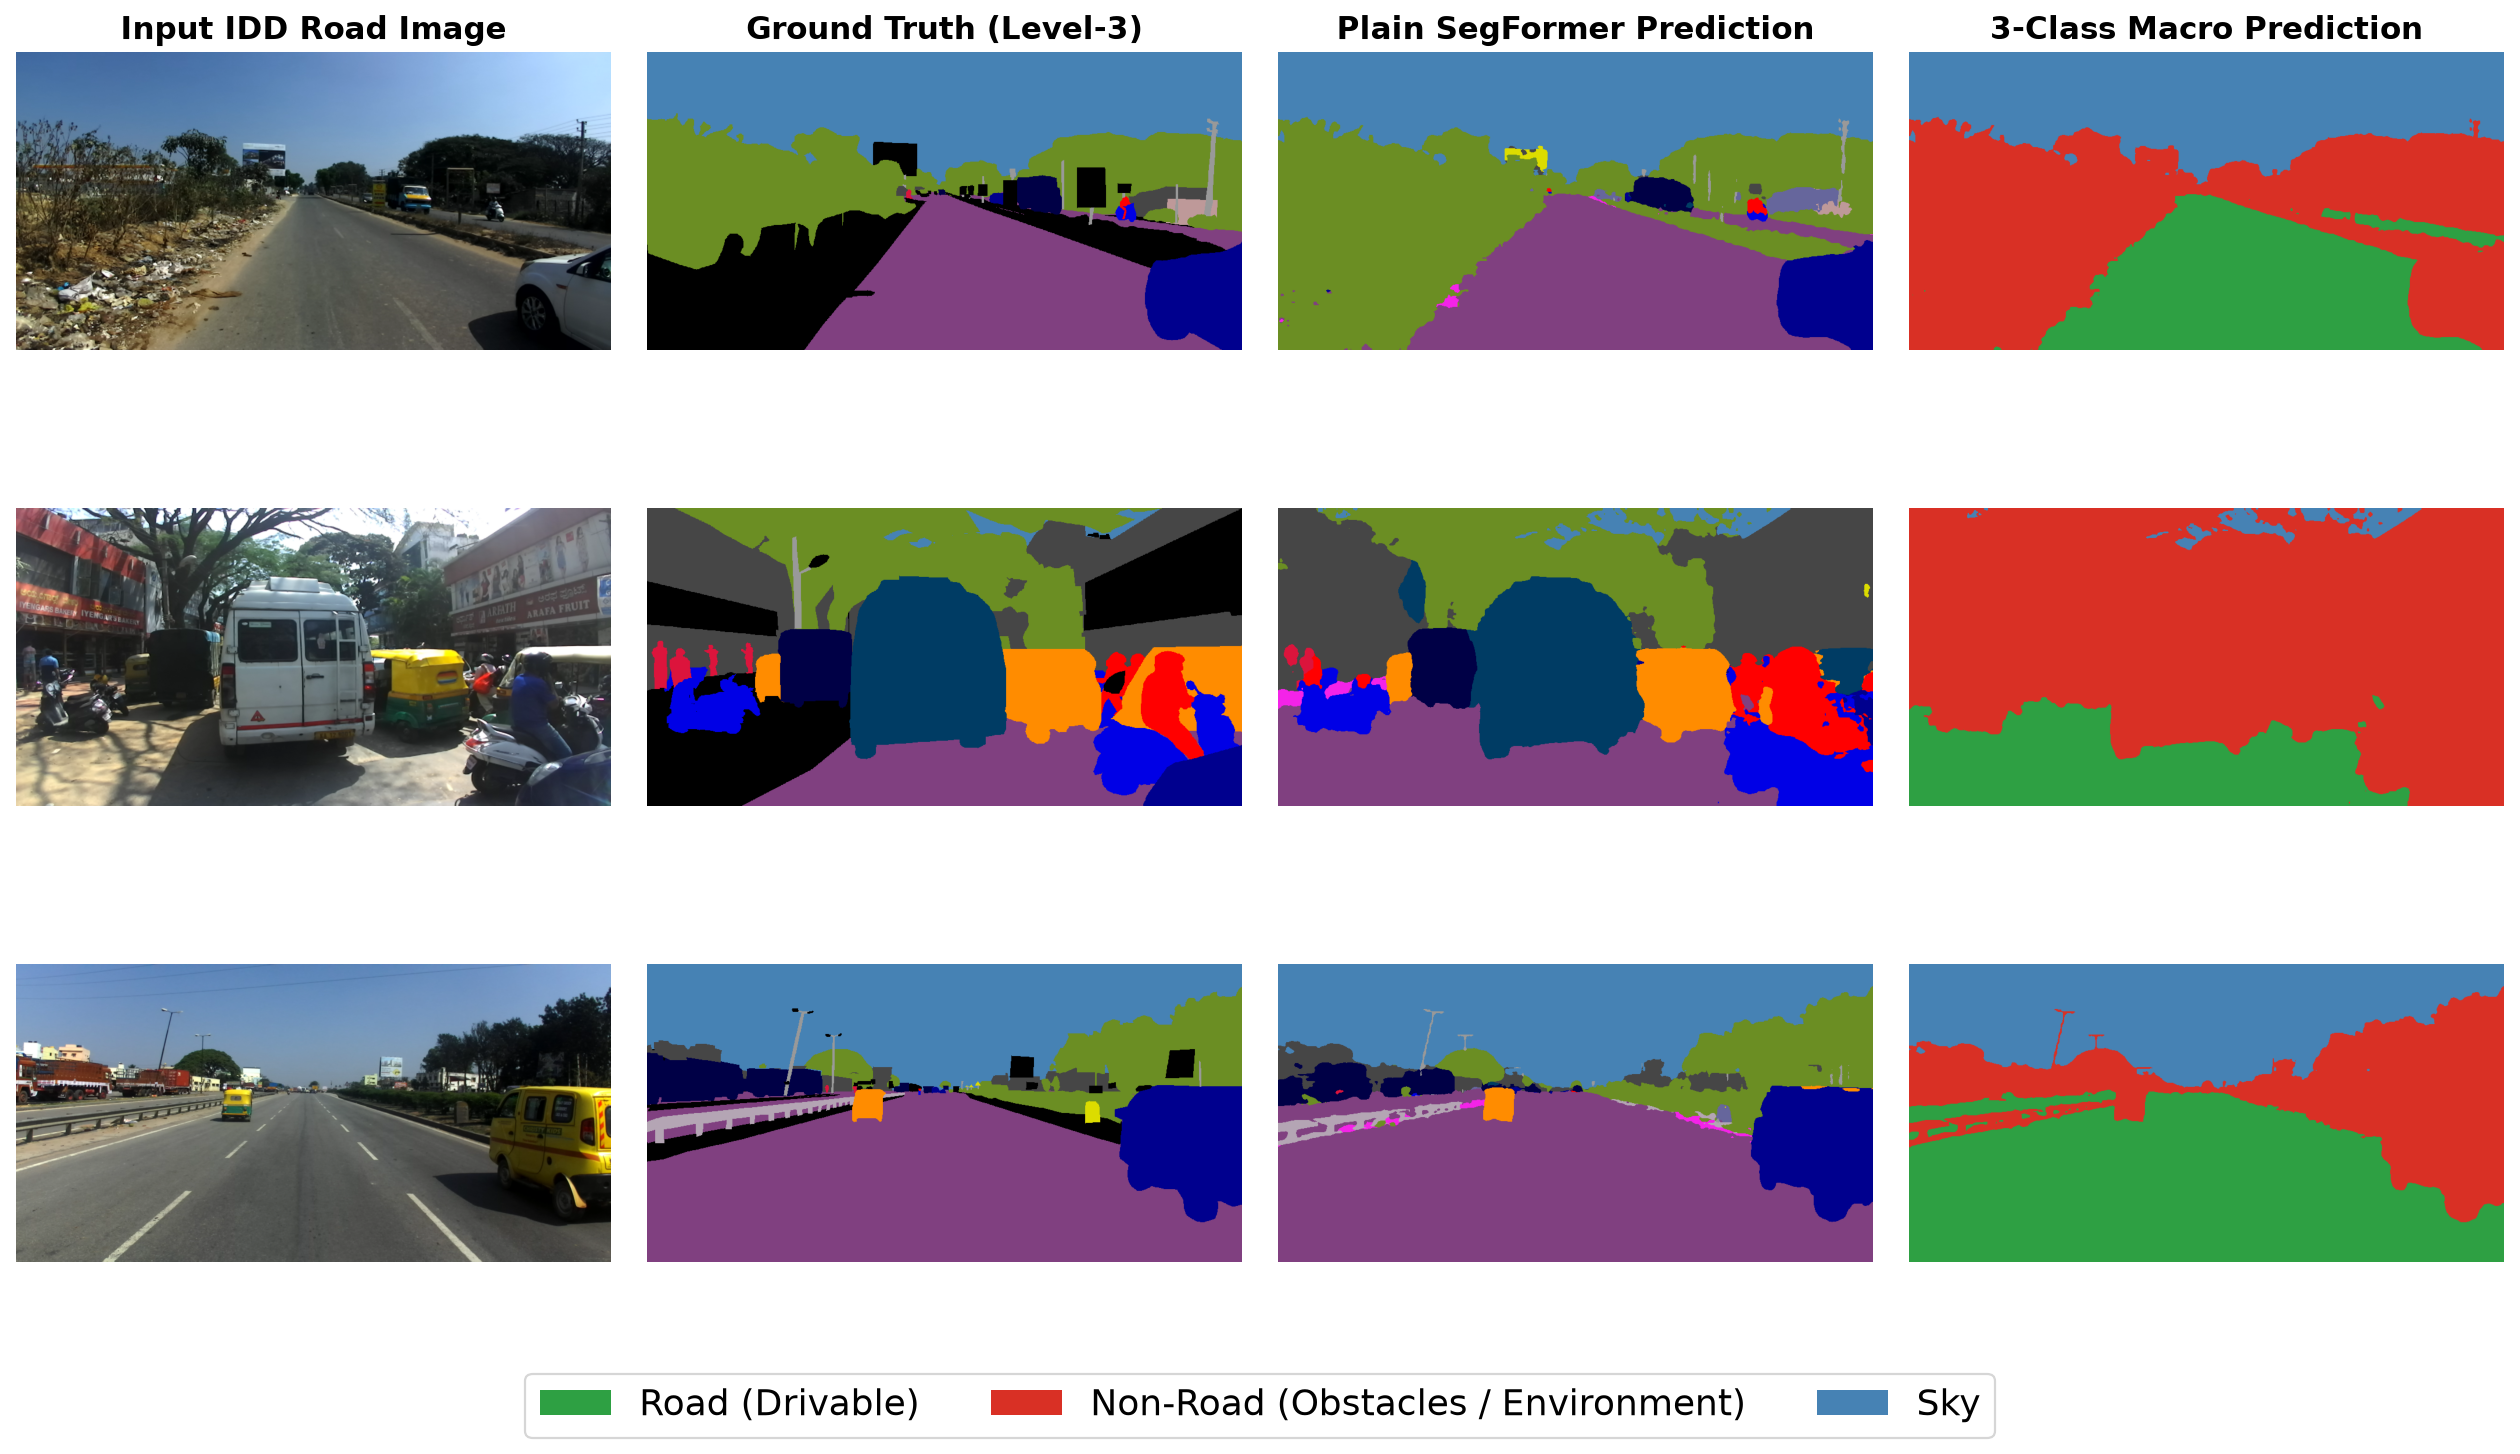

Saved 3-class macro qualitative figure: D:\IDD_Research\aciids2027_outputs\figures\Fig3_segformer_b0_3Class_Macro.png


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

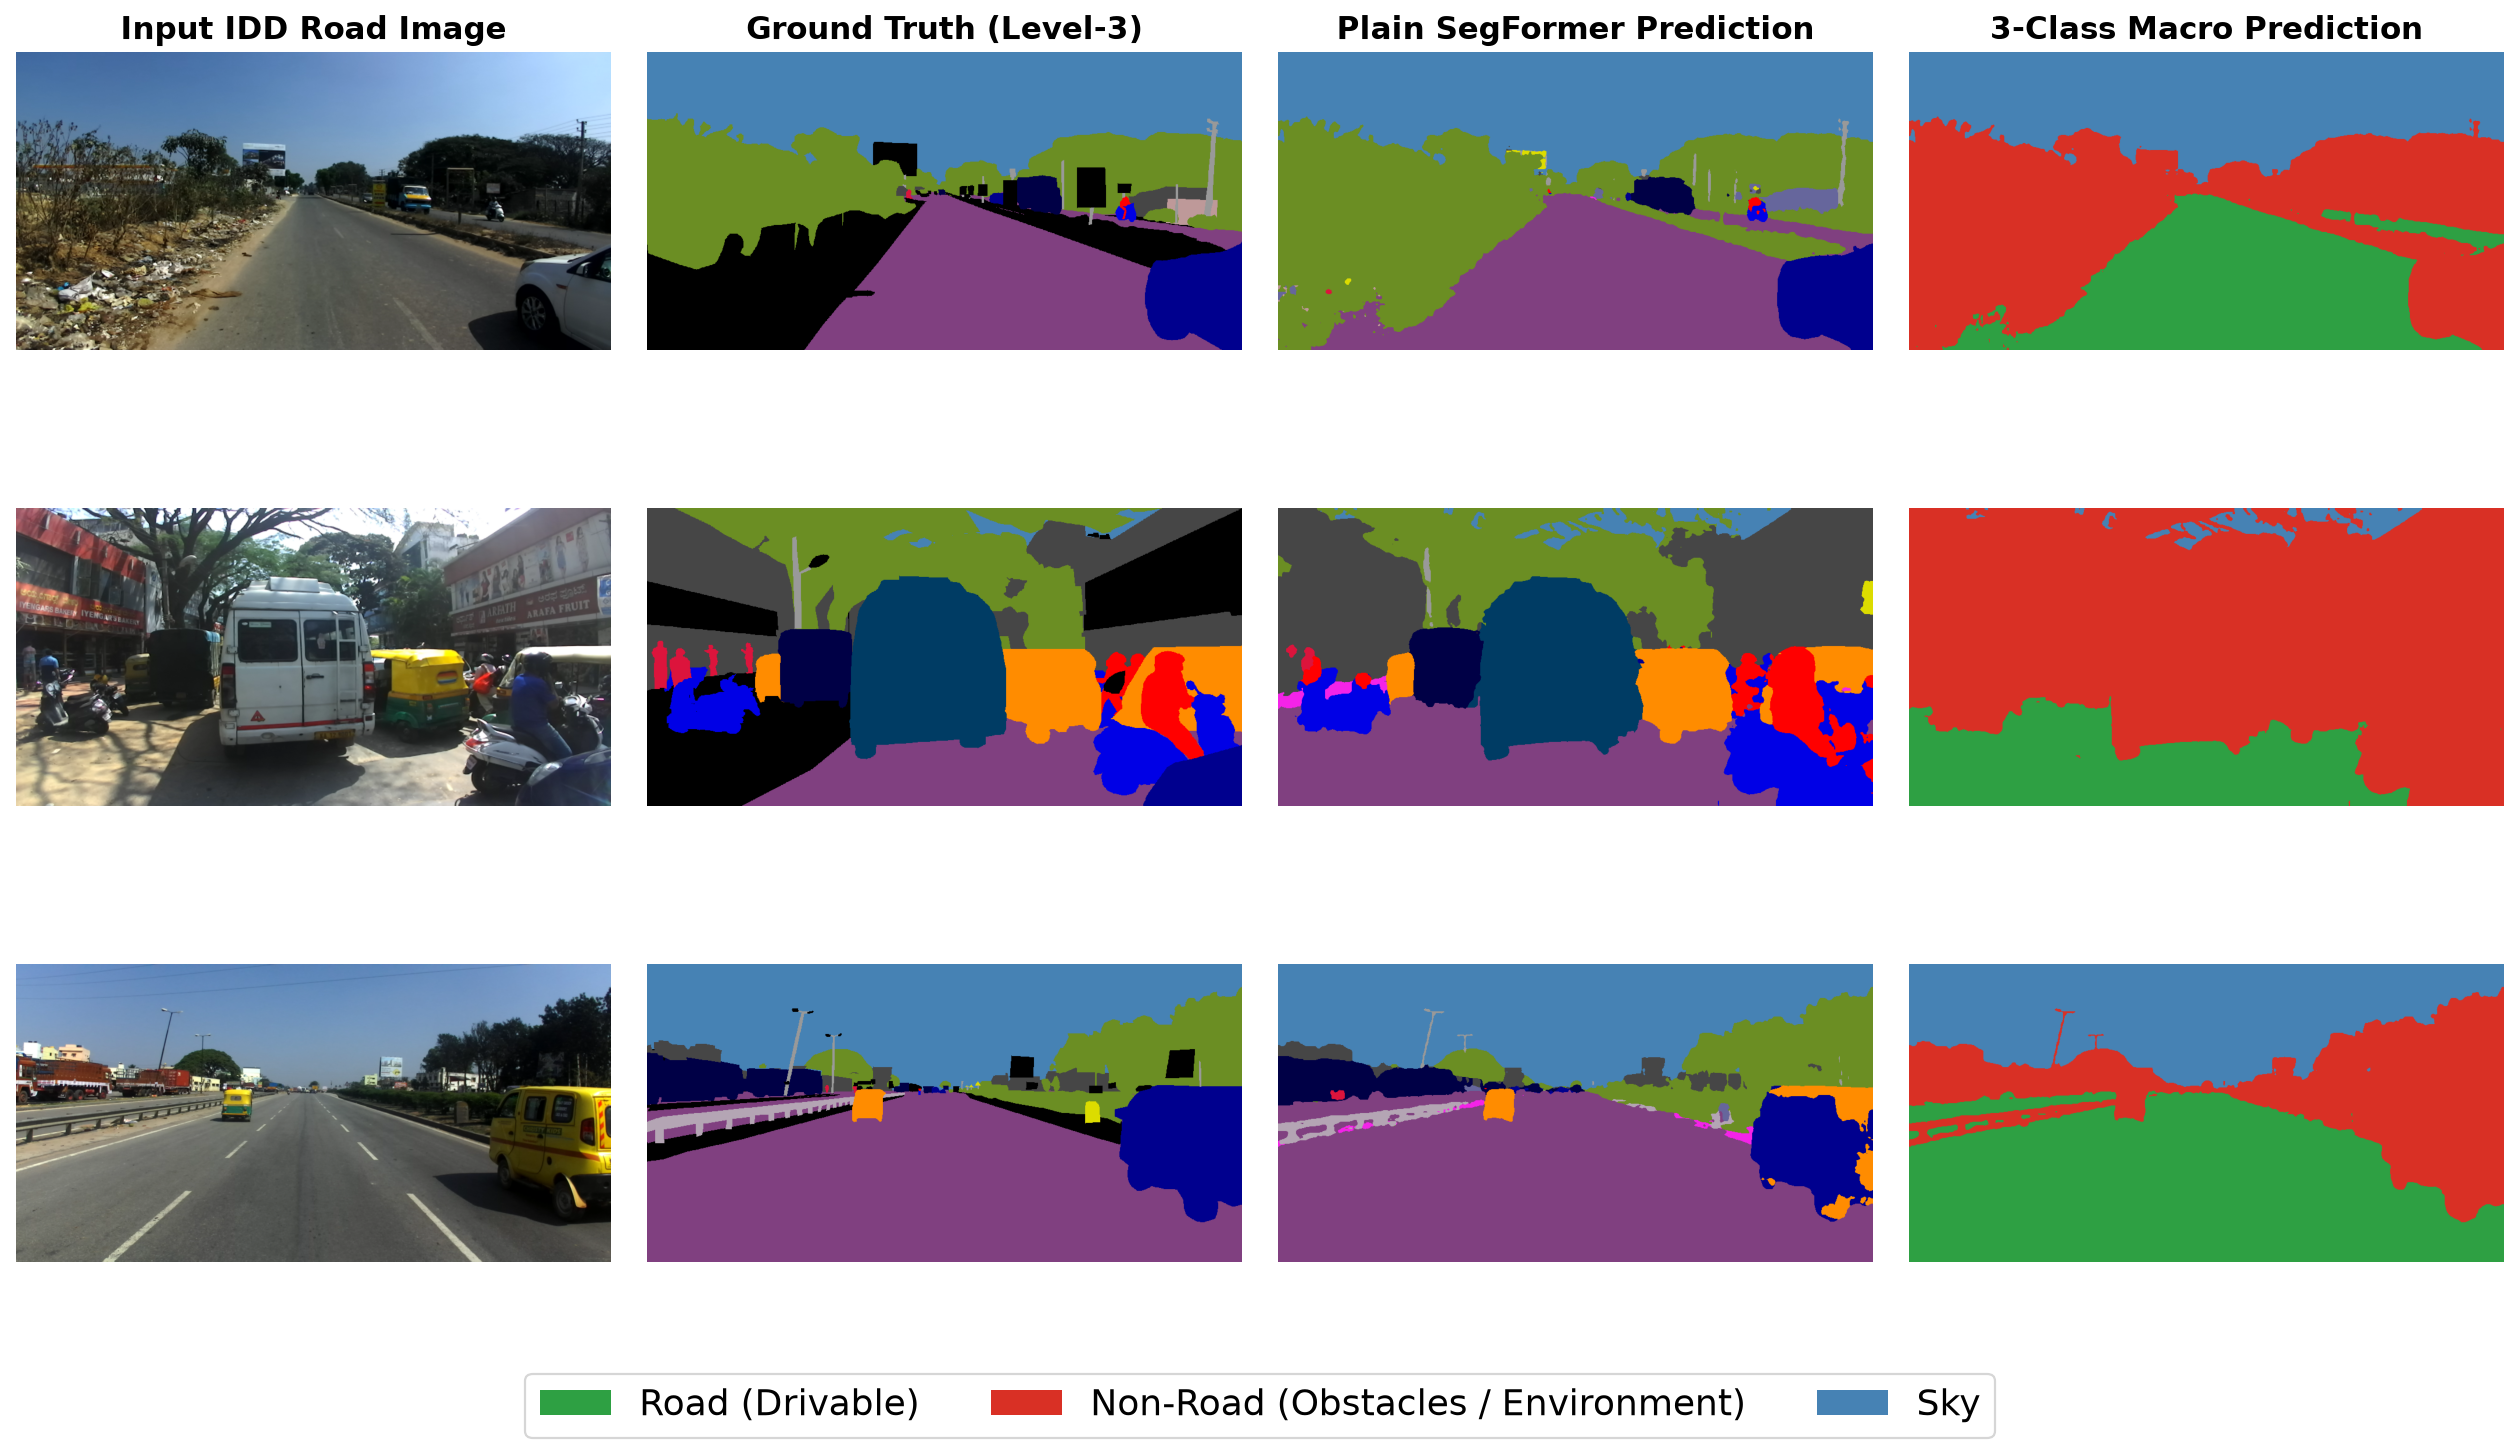

Saved 3-class macro qualitative figure: D:\IDD_Research\aciids2027_outputs\figures\Fig4_segformer_b1_3Class_Macro.png


In [52]:
# ==============================================================================
# CELL 17: QUALITATIVE 3-CLASS MACRO FALLBACK VISUALIZATIONS (FIGURES 3 & 4)
# ==============================================================================
from matplotlib.patches import Patch

# Distinct 26-class color palette for Level-3 & Ground Truth visualization
PALETTE_26 = np.array([
    [128, 64, 128], [250, 170, 160], [244, 35, 232], [230, 150, 140], [70, 70, 70],
    [102, 102, 156], [190, 153, 153], [180, 165, 180], [150, 100, 100], [150, 120, 90],
    [153, 153, 153], [250, 170, 30], [220, 220, 0], [107, 142, 35], [152, 251, 152],
    [70, 130, 180], [220, 20, 60], [255, 0, 0], [0, 0, 142], [0, 0, 70],
    [0, 60, 100], [0, 80, 100], [0, 0, 230], [119, 11, 32], [255, 140, 0], [139, 69, 19]
], dtype=np.uint8)

# 3 Macro-Class Color Palette: Road (Green), Non-Road (Red/Orange), Sky (Blue)
PALETTE_3CLASS = np.array([
    [46, 160, 67],   # 0: Road (Drivable)
    [217, 48, 37],   # 1: Non-Road (Obstacles, Vehicles, Sidewalks, Objects)
    [70, 130, 180]   # 2: Sky
], dtype=np.uint8)

def colorize_l3_mask(mask_2d: np.ndarray) -> np.ndarray:
    H, W = mask_2d.shape
    rgb = np.zeros((H, W, 3), dtype=np.uint8)
    valid = (mask_2d >= 0) & (mask_2d < K3)
    rgb[valid] = PALETTE_26[mask_2d[valid]]
    return rgb

def generate_qualitative_figure(model_name: str, fig_num: int, sample_indices=(5, 25, 60)):
    model = build_model(model_name).to(DEVICE)
    best_ckpt = best_checkpoint_path(model_name)
    if best_ckpt.exists():
        model.load_state_dict(torch.load(best_ckpt, map_location=DEVICE))
    model.eval()

    T_star = OPTIMAL_TEMPS.get(model_name, 1.0)
    
    n_rows = len(sample_indices)
    fig, axes = plt.subplots(n_rows, 4, figsize=(16, 3.2 * n_rows), dpi=160)
    if n_rows == 1:
        axes = np.expand_dims(axes, axis=0)

    with torch.no_grad():
        for r, idx in enumerate(sample_indices):
            img_tensor, gt_tensor = holdout_dataset[idx]
            img_path, _ = holdout_samples[idx]

            # Load RGB image for display
            rgb_vis = Image.open(img_path).convert("RGB").resize((IMAGE_SIZE[1], IMAGE_SIZE[0]), resample=Image.BILINEAR)
            rgb_np = np.array(rgb_vis, dtype=np.uint8)
            gt_np = gt_tensor.numpy()

            inp = img_tensor.unsqueeze(0).to(DEVICE)
            outputs = model(pixel_values=inp)
            up_logits = F.interpolate(outputs.logits, size=IMAGE_SIZE, mode="bilinear", align_corners=False)[0]

            z = up_logits.permute(1, 2, 0) # (H, W, 26)
            p3 = torch.softmax(z / T_star, dim=-1)
            p1 = p3 @ M_3to1 # (H, W, 7) Level-1 probabilities

            # Collapse 7 Level-1 safety groups into 3 Macro-classes:
            # L1 order: [drivable (0), non-drivable (1), living-thing (2), vehicles (3), road-side-objs (4), far-objects (5), sky (6)]
            p_road = p1[:, :, 0:1]                                     # Road
            p_sky = p1[:, :, 6:7]                                      # Sky
            p_non_road = torch.sum(p1[:, :, 1:6], dim=-1, keepdim=True) # Non-Road obstacles & environment

            p_3class = torch.cat([p_road, p_non_road, p_sky], dim=-1) # (H, W, 3)
            _, pred_3class = torch.max(p_3class, dim=-1)
            pred_3class_np = pred_3class.cpu().numpy()

            # Colorize 3-class prediction map
            macro_map = np.zeros((IMAGE_SIZE[0], IMAGE_SIZE[1], 3), dtype=np.uint8)
            for c_id in range(3):
                macro_map[pred_3class_np == c_id] = PALETTE_3CLASS[c_id]

            # Plain prediction colorized for comparison panel 3
            _, pred3 = p3.max(dim=-1)
            pred3_np = pred3.cpu().numpy()

            panels = [
                (rgb_np, "Input IDD Road Image"),
                (colorize_l3_mask(gt_np), "Ground Truth (Level-3)"),
                (colorize_l3_mask(pred3_np), "Plain SegFormer Prediction"),
                (macro_map, "3-Class Macro Prediction")
            ]
            for c, (img_arr, title) in enumerate(panels):
                axes[r, c].imshow(img_arr)
                axes[r, c].axis("off")
                if r == 0:
                    axes[r, c].set_title(title, fontsize=14, fontweight="bold")

    legend_elements = [
        Patch(facecolor="#2ea043", label="Road (Drivable)"),
        Patch(facecolor="#d93025", label="Non-Road (Obstacles / Environment)"),
        Patch(facecolor="#4682b4", label="Sky")
    ]
    fig.legend(handles=legend_elements, loc="lower center", ncol=3, fontsize=16, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout()
    out_file = FIGURE_DIR / f"Fig{fig_num}_{model_name}_3Class_Macro.png"
    fig.savefig(out_file, dpi=300, bbox_inches="tight")
    plt.show()

    del model
    torch.cuda.empty_cache()
    gc.collect()
    print(f"Saved 3-class macro qualitative figure: {out_file.resolve()}")

generate_qualitative_figure("segformer_b0", fig_num=3, sample_indices=(5, 25, 60))
generate_qualitative_figure("segformer_b1", fig_num=4, sample_indices=(5, 25, 60))

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[-] Loading checkpoint weights for segformer_b1 from aciids2027_outputs\checkpoints\segformer_b1_best.pt...


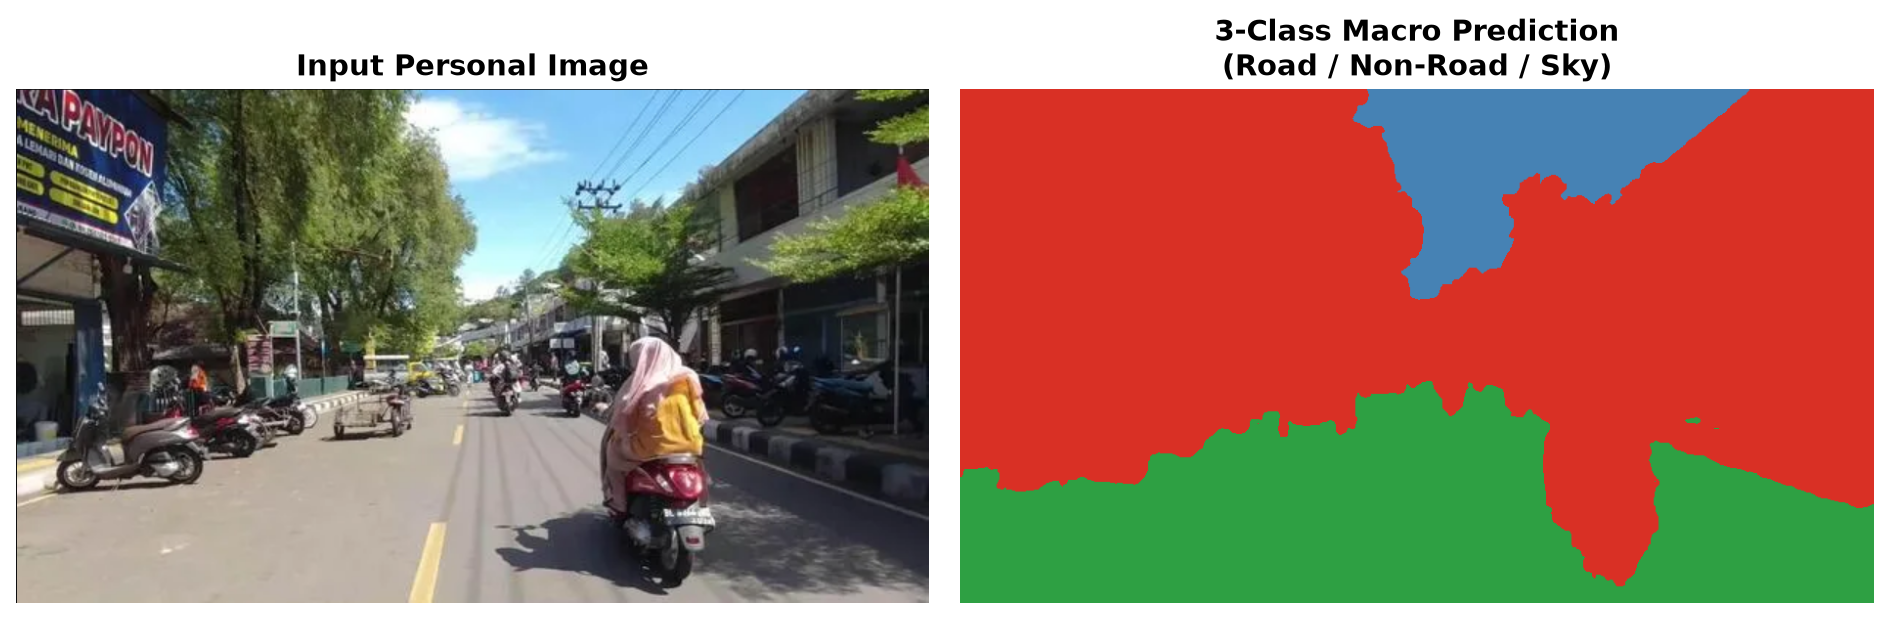

[+] Personal image inference complete! Saved plot to: D:\IDD_Research\aciids2027_outputs\figures\personal_image_3class_prediction.png


In [24]:
# ==============================================================================
# CELL 18: CUSTOM INFERENCE & 3-CLASS MACRO PREDICTION ON A PERSONAL IMAGE
# ==============================================================================
import matplotlib.pyplot as plt
from PIL import Image
import torch
import numpy as np
import torch.nn.functional as F

def predict_personal_image(model_name: str, image_path: str):
    """Load a trained checkpoint, run inference on a custom personal image, 
       and output a 3-class macro prediction (Road, Non-Road, Sky)."""
    
    # 1. Build and load model weights onto active device
    model = build_model(model_name).to(DEVICE)
    best_ckpt = best_checkpoint_path(model_name)
    if best_ckpt.exists():
        print(f"[-] Loading checkpoint weights for {model_name} from {best_ckpt}...")
        model.load_state_dict(torch.load(best_ckpt, map_location=DEVICE))
    else:
        print(f"[!] Warning: Checkpoint not found at {best_ckpt}. Using base weights.")
    
    model.eval()
    T_star = OPTIMAL_TEMPS.get(model_name, 1.0)

    # 2. Load and preprocess the custom personal image
    path = Path(image_path)
    if not path.exists():
        raise FileNotFoundError(f"Could not find personal image at: {path.resolve()}")
        
    img_pil = Image.open(path).convert("RGB")
    orig_size = img_pil.size # (Width, Height)
    
    # Resize to model input size (Height, Width)
    img_resized = img_pil.resize((IMAGE_SIZE[1], IMAGE_SIZE[0]), resample=Image.BILINEAR)
    img_np = np.array(img_resized, dtype=np.float32) / 255.0
    
    # Normalize using dataset mean and std
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    img_norm = (img_np - mean) / std
    
    # Convert to tensor: (1, 3, H, W)
    img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE)

    # 3. Perform forward pass and hierarchical projection
    with torch.no_grad():
        outputs = model(pixel_values=img_tensor)
        # Upsample logits back to full input resolution
        up_logits = F.interpolate(outputs.logits, size=IMAGE_SIZE, mode="bilinear", align_corners=False)[0] # (26, H, W)

        z = up_logits.permute(1, 2, 0) # (H, W, 26)
        p3 = torch.softmax(z / T_star, dim=-1)
        p1 = p3 @ M_3to1             # (H, W, 7) Level-1 safety group probabilities

        # Collapse 7 Level-1 groups into 3 Macro-classes:
        # L1 order: [drivable (0), non-drivable (1), living-thing (2), vehicles (3), road-side-objs (4), far-objects (5), sky (6)]
        p_road = p1[:, :, 0:1]                                     # Road
        p_sky = p1[:, :, 6:7]                                      # Sky
        p_non_road = torch.sum(p1[:, :, 1:6], dim=-1, keepdim=True) # Non-Road obstacles & environment

        p_3class = torch.cat([p_road, p_non_road, p_sky], dim=-1) # (H, W, 3)
        _, pred_3class = torch.max(p_3class, dim=-1)
        pred_3class_np = pred_3class.cpu().numpy()

    # 4. Colorize 3-Class Macro Prediction Map
    # 0: Road (Green), 1: Non-Road (Red), 2: Sky (Blue)
    PALETTE_3CLASS = np.array([
        [46, 160, 67],   # Road
        [217, 48, 37],   # Non-Road
        [70, 130, 180]   # Sky
    ], dtype=np.uint8)

    macro_map = np.zeros((IMAGE_SIZE[0], IMAGE_SIZE[1], 3), dtype=np.uint8)
    for c_id in range(3):
        macro_map[pred_3class_np == c_id] = PALETTE_3CLASS[c_id]

    # Resize back to original image dimensions for clear side-by-side inspection
    macro_map_pil = Image.fromarray(macro_map).resize(orig_size, resample=Image.NEAREST)

    # 5. Plot Results
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), dpi=160)
    axes[0].imshow(img_pil)
    axes[0].set_title("Input Personal Image", fontsize=13, fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(macro_map_pil)
    axes[1].set_title("3-Class Macro Prediction\n(Road / Non-Road / Sky)", fontsize=13, fontweight="bold")
    axes[1].axis("off")

    fig.tight_layout()
    out_path = FIGURE_DIR / "personal_image_3class_prediction.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"[+] Personal image inference complete! Saved plot to: {out_path.resolve()}")

    # Cleanup memory
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

# ==============================================================================
# EXECUTE INFERENCE (Change path to your actual personal test image)
# ==============================================================================
personal_image_path = r"D:\IDD_Research\indian_traffic.png" # <-- Update path to your image
predict_personal_image("segformer_b1", personal_image_path)